In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\truths.csv"
)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"File not found: {DATA_PATH}")

# Load original data without modifying the source file
df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False
)

print(f"Original records: {len(df_raw):,}")
print(f"Original columns: {df_raw.shape[1]}")

Original records: 1,051,149
Original columns: 13


## Removing Exact Duplicates

In [2]:
# Create a working copy
df_clean = df_raw.copy()

# Count exact duplicates
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("DUPLICATE REMOVAL")
print("---------------------------")
print(f"Original records: {len(df_raw):,}")
print(f"Exact duplicates removed: {duplicates_before:,}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Remaining exact duplicates: {df_clean.duplicated().sum():,}")

# Validate the result
assert df_clean.duplicated().sum() == 0

DUPLICATE REMOVAL
---------------------------
Original records: 1,051,149
Exact duplicates removed: 12,324
Remaining records: 1,038,825
Remaining exact duplicates: 0


## Converting Data Types

In [3]:
# Convert identifiers
df_clean["id"] = pd.to_numeric(
    df_clean["id"], errors="raise"
).astype("Int64")

df_clean["author"] = pd.to_numeric(
    df_clean["author"].replace("", pd.NA),
    errors="raise"
).astype("Int64")

# Convert timestamps
for col in ["timestamp", "time_scraped"]:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="ISO8601",
        errors="raise"
    )

# Convert boolean columns
boolean_mapping = {"t": True, "f": False}

for col in ["is_retruth", "is_reply"]:
    df_clean[col] = (
        df_clean[col]
        .map(boolean_mapping)
        .astype("boolean")
    )

# Convert engagement metrics
engagement_cols = [
    "like_count",
    "retruth_count",
    "reply_count"
]

for col in engagement_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="raise"
    ).astype("Int64")

print("DATA TYPES AFTER CLEANING")
print("---------------------------")
display(df_clean.dtypes)

print("\nMissing values after conversion:")
display(df_clean.isna().sum())

DATA TYPES AFTER CLEANING
---------------------------


id                          Int64
timestamp          datetime64[us]
time_scraped       datetime64[us]
is_retruth                boolean
is_reply                  boolean
author                      Int64
like_count                  Int64
retruth_count               Int64
reply_count                 Int64
text                       string
external_id                string
url                        string
truth_retruthed            string
dtype: object


Missing values after conversion:


id                   0
timestamp            0
time_scraped         0
is_retruth           0
is_reply             0
author             145
like_count           0
retruth_count        0
reply_count          0
text                 0
external_id          0
url                  0
truth_retruthed      0
dtype: int64

In [4]:
# Identify missing author IDs
missing_author_mask = (
    df_clean["author"].isna()
)

missing_authors = df_clean.loc[missing_author_mask].copy()

print("MISSING AUTHOR ANALYSIS")
print("---------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Missing authors: {len(missing_authors):,}")
print(f"Missing percentage: {missing_author_mask.mean() * 100:.4f}%")

# Inspect relevant columns
display(
    missing_authors[
        ["id", "author", "external_id", "url"]
    ].head(15)
)

MISSING AUTHOR ANALYSIS
---------------------------
Total records: 1,038,825
Missing authors: 145
Missing percentage: 0.0140%


,id,author,external_id,url
134639,895511,<NA>,truthtent,108864982160272342
134654,895527,<NA>,JackPosobiec,108822381542261053
134663,895535,<NA>,JohnPaulMacIsaac,108814846897812544
134664,895536,<NA>,Lara45,109073924301696705
134679,895573,<NA>,JackPosobiec,108639442992116282
134683,895587,<NA>,MelaniaTrump,109027164115408705
134686,895595,<NA>,NewsMax,109017355982286163
134692,895553,<NA>,DonaldJTrumpJr,108712395933363004
135661,897718,<NA>,doug4gov,109105436245928682
136412,899018,<NA>,PepeLivesMatter,107922117579592120


In [5]:
# Extract usernames from canonical Truth Social URLs
df_clean["username_from_url"] = (
    df_clean["url"]
    .astype("string")
    .str.extract(
        r"(?i)^https?://(?:www\.)?truthsocial\.com/@([^/?#]+)/posts/",
        expand=False
    )
    .str.lower()
)

# Build mappings using records with known author IDs
known_authors = df_clean[
    df_clean["author"].notna()
    & df_clean["username_from_url"].notna()
].copy()

# Count distinct authors per username
username_author_counts = (
    known_authors.groupby("username_from_url")["author"]
    .nunique()
)

# Keep only unambiguous mappings
valid_usernames = username_author_counts[
    username_author_counts == 1
].index

username_to_author = (
    known_authors[
        known_authors["username_from_url"].isin(valid_usernames)
    ]
    .groupby("username_from_url")["author"]
    .first()
)

print("USERNAME-AUTHOR MAPPING")
print("---------------------------")
print(f"Unique usernames: {len(username_author_counts):,}")
print(f"Unambiguous mappings: {len(username_to_author):,}")
print(f"Ambiguous mappings: {(username_author_counts > 1).sum():,}")

USERNAME-AUTHOR MAPPING
---------------------------
Unique usernames: 18,634
Unambiguous mappings: 18,631
Ambiguous mappings: 3


In [6]:
# Candidate username from external_id
external_username = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Consider external_id only when it looks like a username
external_username = external_username.where(
    external_username.str.fullmatch(
        r"[a-z0-9_]+",
        na=False
    )
    & external_username.str.contains(
        r"[a-z_]",
        na=False
    )
)

# Match both potential sources against known author mappings
author_from_url = (
    df_clean["username_from_url"].map(username_to_author)
)

author_from_external = (
    external_username.map(username_to_author)
)

# Detect conflicting candidates
conflicting_candidates = (
    missing_author_mask
    & author_from_url.notna()
    & author_from_external.notna()
    & author_from_url.ne(author_from_external).fillna(False)
)

# Prefer username extracted from the canonical URL
author_candidate = author_from_url.combine_first(
    author_from_external
)

# Exclude conflicting evidence
recoverable_mask = (
    missing_author_mask
    & author_candidate.notna()
    & ~conflicting_candidates
)

print("AUTHOR RECOVERY CANDIDATES")
print("---------------------------")
print(f"Missing authors: {missing_author_mask.sum():,}")
print(f"Recoverable candidates: {recoverable_mask.sum():,}")
print(f"Conflicting candidates: {conflicting_candidates.sum():,}")
print(f"Unresolved: {(missing_author_mask & ~recoverable_mask).sum():,}")

display(
    df_clean.loc[
        recoverable_mask,
        ["id", "author", "external_id", "url"]
    ].assign(
        inferred_author=author_candidate.loc[recoverable_mask]
    ).head(15)
)

AUTHOR RECOVERY CANDIDATES
---------------------------
Missing authors: 145
Recoverable candidates: 58
Conflicting candidates: 0
Unresolved: 87


,id,author,external_id,url,inferred_author
134683,895587,<NA>,MelaniaTrump,109027164115408705,559
134686,895595,<NA>,NewsMax,109017355982286163,145
134692,895553,<NA>,DonaldJTrumpJr,108712395933363004,300
136412,899018,<NA>,PepeLivesMatter,107922117579592120,1343
145236,914237,<NA>,TravisTritt,107849593147323752,206
145368,915764,<NA>,DoItPepe,109119256185776036,9596
145435,914431,<NA>,VeBo1991,108202334611281775,2477
145447,914450,<NA>,RealCarolLeek,108015702747545270,21479
145454,914456,<NA>,jkk4782,107998916362910992,7983
145480,914466,<NA>,ThePatriotVoice,107981749571692604,928


In [7]:
# Preserve information about imputed author IDs
df_clean["author_imputed"] = False

# Fill missing author IDs using validated candidates
df_clean.loc[recoverable_mask, "author"] = (
    author_candidate.loc[recoverable_mask].astype("Int64")
)

# Flag imputed records
df_clean.loc[recoverable_mask, "author_imputed"] = True

# Final validation
print("AUTHOR IMPUTATION RESULTS")
print("---------------------------")
print(f"Missing authors before: {missing_author_mask.sum():,}")
print(f"Authors recovered: {df_clean['author_imputed'].sum():,}")
print(f"Missing authors after: {df_clean['author'].isna().sum():,}")

assert (
    df_clean["author_imputed"].sum()
    + df_clean["author"].isna().sum()
    == missing_author_mask.sum()
)

AUTHOR IMPUTATION RESULTS
---------------------------
Missing authors before: 145
Authors recovered: 58
Missing authors after: 87


In [8]:
# Count supporting observations for each username-author mapping
mapping_support = (
    known_authors.groupby("username_from_url")
    .size()
)

# Get usernames used for imputations
imputed_usernames = (
    df_clean["username_from_url"]
    .combine_first(external_username)
)

# Inspect supporting evidence for recovered authors
validation_df = pd.DataFrame({
    "truth_id": df_clean.loc[df_clean["author_imputed"], "id"],
    "imputed_author": df_clean.loc[df_clean["author_imputed"], "author"],
    "username": imputed_usernames.loc[df_clean["author_imputed"]]
})

validation_df["supporting_records"] = (
    validation_df["username"]
    .map(mapping_support)
)

print("IMPUTATION VALIDATION")
print("---------------------------")

display(
    validation_df.sort_values(
        "supporting_records",
        ascending=True
    ).head(20)
)

print("\nMappings supported by one observation:",
      (validation_df["supporting_records"] == 1).sum())

IMPUTATION VALIDATION
---------------------------


,truth_id,imputed_author,username,supporting_records
145435,914431,2477,vebo1991,1
145454,914456,7983,jkk4782,1
145480,914466,928,thepatriotvoice,1
158668,938012,2081,repgregsteube,1
159769,939902,122,govrondesantis,1
160999,942084,122,govrondesantis,1
160910,941997,207,hodgetwins,1
160937,942039,122,govrondesantis,1
160988,942075,122,govrondesantis,1
161253,942434,9287,patriotflyer,1



Mappings supported by one observation: 11


In [9]:
# Identify the exact username used for each imputation
actual_imputation_username = (
    df_clean["username_from_url"]
    .where(author_from_url.notna())
    .combine_first(
        external_username.where(author_from_external.notna())
    )
)

# Reconstruct the author from the actual mapping
validated_author = actual_imputation_username.map(
    username_to_author
)

# Verify imputed author IDs
imputation_matches = (
    df_clean.loc[df_clean["author_imputed"], "author"]
    .eq(validated_author.loc[df_clean["author_imputed"]])
)

print("IMPUTATION CONSISTENCY CHECK")
print("---------------------------")
print(f"Imputed authors: {df_clean['author_imputed'].sum()}")
print(f"Consistent imputations: {imputation_matches.sum()}")
print(f"Inconsistent imputations: {(~imputation_matches).sum()}")

IMPUTATION CONSISTENCY CHECK
---------------------------
Imputed authors: 58
Consistent imputations: 58
Inconsistent imputations: 0


In [10]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd

# Define the path to users.xml
USERS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\users.xml"
)

if not USERS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {USERS_PATH}")

# Parse the XML file
tree = ET.parse(USERS_PATH)
root = tree.getroot()

print("USERS.XML STRUCTURE")
print("---------------------------")
print("Root tag:", root.tag)
print("Number of direct child elements:", len(root))

# Inspect the first user records
for user in list(root)[:3]:
    print("\nUser tag:", user.tag)
    print("Attributes:", user.attrib)

    for child in user:
        print(f"  {child.tag}: {child.text}")

USERS.XML STRUCTURE
---------------------------
Root tag: data
Number of direct child elements: 487292

User tag: row
Attributes: {}
  id_user: 1238
  timestamp_user_creation: 2022-02-01 00:00:00
  username: jeffgolfs
  follower_count: 886
  following_count: 204
  profile_url: https://truthsocial.com/@jeffgolfs
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f

User tag: row
Attributes: {}
  id_user: 50
  timestamp_user_creation: 2022-02-01 00:00:00
  username: MizW
  follower_count: 2365
  following_count: 2929
  profile_url: https://truthsocial.com/@MizW
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f

User tag: row
Attributes: {}
  id_user: 6951
  timestamp_user_creation: 2022-02-01 00:00:00
  username: SusanCreech
  follower_count: 870
  following_count: 1232
  profile_url: https://truthsocial.com/@SusanCreech
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f


In [11]:
# Extract relevant fields from users.xml
users_records = []

for user in root.findall("row"):
    users_records.append({
        "id_user": user.findtext("id_user"),
        "username": user.findtext("username")
    })

users_df = pd.DataFrame(users_records)

# Normalize usernames
users_df["username_clean"] = (
    users_df["username"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert user IDs to numeric
users_df["id_user"] = pd.to_numeric(
    users_df["id_user"],
    errors="coerce"
).astype("Int64")

# Remove incomplete records
users_valid = users_df.dropna(
    subset=["username_clean", "id_user"]
).copy()

users_valid = users_valid[
    users_valid["username_clean"].ne("")
]

# Identify unambiguous username-to-ID mappings
username_counts = (
    users_valid.groupby("username_clean")["id_user"]
    .nunique()
)

valid_usernames = username_counts[
    username_counts == 1
].index

users_mapping = (
    users_valid[
        users_valid["username_clean"].isin(valid_usernames)
    ]
    .groupby("username_clean")["id_user"]
    .first()
)

print("USERS.XML MAPPING")
print("---------------------------")
print(f"Total users: {len(users_df):,}")
print(f"Valid username mappings: {len(users_mapping):,}")
print(f"Ambiguous usernames: {(username_counts > 1).sum():,}")

USERS.XML MAPPING
---------------------------
Total users: 487,292
Valid username mappings: 487,068
Ambiguous usernames: 80


In [12]:
# Extract username candidates from existing columns
username_from_external = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Select username from URL when available,
# otherwise use external_id
username_candidate = (
    df_clean["username_from_url"]
    .combine_first(username_from_external)
)

# Retrieve author IDs from users.xml
author_from_users = username_candidate.map(users_mapping)

# Check previously imputed authors
previously_imputed = df_clean["author_imputed"]

validation = pd.DataFrame({
    "author_imputed": df_clean.loc[previously_imputed, "author"],
    "author_users_xml": author_from_users.loc[previously_imputed]
})

confirmed = (
    validation["author_users_xml"].notna()
    & validation["author_imputed"].eq(
        validation["author_users_xml"]
    ).fillna(False)
)

conflicting = (
    validation["author_users_xml"].notna()
    & validation["author_imputed"].ne(
        validation["author_users_xml"]
    ).fillna(False)
)

print("PREVIOUS IMPUTATION VALIDATION")
print("---------------------------")
print(f"Previously imputed: {len(validation):,}")
print(f"Confirmed by users.xml: {confirmed.sum():,}")
print(f"Conflicting mappings: {conflicting.sum():,}")
print(f"Not found in users.xml: {validation['author_users_xml'].isna().sum():,}")

display(validation.head(15))

PREVIOUS IMPUTATION VALIDATION
---------------------------
Previously imputed: 58
Confirmed by users.xml: 58
Conflicting mappings: 0
Not found in users.xml: 0


,author_imputed,author_users_xml
134683,559,559
134686,145,145
134692,300,300
136412,1343,1343
145236,206,206
145368,9596,9596
145435,2477,2477
145447,21479,21479
145454,7983,7983
145480,928,928


In [13]:
# Identify remaining missing authors
still_missing = df_clean["author"].isna()

# Find recoverable authors using users.xml
recoverable_from_users = (
    still_missing
    & author_from_users.notna()
)

print("CROSS-DATASET AUTHOR RECOVERY")
print("---------------------------")
print(f"Missing authors before: {still_missing.sum():,}")
print(f"Recoverable from users.xml: {recoverable_from_users.sum():,}")
print(f"Still unresolved: {(still_missing & ~recoverable_from_users).sum():,}")

# Inspect candidate matches before applying changes
display(
    df_clean.loc[
        recoverable_from_users,
        ["id", "external_id", "url", "author"]
    ].assign(
        inferred_author=author_from_users.loc[recoverable_from_users]
    ).head(20)
)

CROSS-DATASET AUTHOR RECOVERY
---------------------------
Missing authors before: 87
Recoverable from users.xml: 87
Still unresolved: 0


,id,external_id,url,author,inferred_author
134639,895511,truthtent,108864982160272342,<NA>,11214
134654,895527,JackPosobiec,108822381542261053,<NA>,143
134663,895535,JohnPaulMacIsaac,108814846897812544,<NA>,2098
134664,895536,Lara45,109073924301696705,<NA>,933
134679,895573,JackPosobiec,108639442992116282,<NA>,143
135661,897718,doug4gov,109105436245928682,<NA>,1413
145137,914125,Elajane,107943822372142377,<NA>,4817
145149,914135,sweetwatergirl,107924695598414362,<NA>,17391
145153,914148,xGoldylocsx,107911657290583986,<NA>,8032
145229,914225,DavidKirkland,107918278278888247,<NA>,40850


In [14]:
# Track which authors were recovered using users.xml
df_clean["author_imputed_users"] = False

# Fill remaining missing author IDs
df_clean.loc[recoverable_from_users, "author"] = (
    author_from_users.loc[recoverable_from_users]
    .astype("Int64")
)

# Mark recovered records
df_clean.loc[recoverable_from_users, "author_imputed_users"] = True

print("FINAL AUTHOR RECOVERY RESULTS")
print("---------------------------")
print(f"Recovered using truths.csv: {df_clean['author_imputed'].sum():,}")
print(f"Recovered using users.xml: {df_clean['author_imputed_users'].sum():,}")
print(f"Total recovered: {(df_clean['author_imputed'] | df_clean['author_imputed_users']).sum():,}")
print(f"Missing authors remaining: {df_clean['author'].isna().sum():,}")

FINAL AUTHOR RECOVERY RESULTS
---------------------------
Recovered using truths.csv: 58
Recovered using users.xml: 87
Total recovered: 145
Missing authors remaining: 0


## Handling Text Problems - MV and <

In [15]:
# Identify missing and malformed text values
text_series = df_clean["text"].astype("string")

# Empty or missing text
missing_text_mask = (
    text_series.isna()
    | text_series.str.strip().eq("")
)

# Text containing only "<"
less_than_mask = (
    text_series.str.strip().eq("<")
)

# Combined problematic records
problematic_text_mask = (
    missing_text_mask | less_than_mask
).fillna(False)

print("TEXT DATA QUALITY ANALYSIS")
print("---------------------------")
print(f"Total Truths: {len(df_clean):,}")
print(f"Missing/empty text: {missing_text_mask.sum():,}")
print(f"Text containing only '<': {less_than_mask.sum():,}")
print(f"Total problematic texts: {problematic_text_mask.sum():,}")
print(f"Percentage affected: {problematic_text_mask.mean() * 100:.2f}%")

# Inspect problematic records
display(
    df_clean.loc[
        problematic_text_mask,
        ["id", "external_id", "url", "author",
         "is_retruth", "is_reply", "text"]
    ].head(20)
)

TEXT DATA QUALITY ANALYSIS
---------------------------
Total Truths: 1,038,825
Missing/empty text: 176
Text containing only '<': 5,423
Total problematic texts: 5,599
Percentage affected: 0.54%


,id,external_id,url,author,is_retruth,is_reply,text
1167,807655,CeceBloomwood,107925568586381393,20054,True,False,
1193,704620,PadingtonRose,108442301408485705,11225,True,False,<
1227,704633,PadingtonRose,108434546171751458,11225,True,False,<
1244,804752,marknicholson,109104919259283807,20030,False,False,
1263,807647,CeceBloomwood,107959581599419915,20054,True,False,
10026,713325,pandyls,108241213535601948,16161,True,False,<
10045,713386,pandyls,108205161088669367,16161,True,False,<
10052,805569,marknicholson,108244712793725159,20030,True,True,
15831,720084,J6_Insurrectionist,108776517385844471,16733,True,False,<
15842,720115,PatriotAR,108642821558716084,8017,True,False,<


In [16]:
# Identify records with usable text
valid_text_mask = (
    ~problematic_text_mask
)

# Count distinct valid texts for each Truth ID
valid_text_counts = (
    df_clean.loc[valid_text_mask]
    .groupby("id")["text"]
    .nunique()
)

# Only retain IDs associated with exactly one valid text
unambiguous_ids = valid_text_counts[
    valid_text_counts == 1
].index

# Build an ID-to-text mapping
text_mapping = (
    df_clean.loc[
        valid_text_mask
        & df_clean["id"].isin(unambiguous_ids)
    ]
    .groupby("id")["text"]
    .first()
)

# Find recovery candidates
recovered_text_candidates = df_clean["id"].map(
    text_mapping
)

recoverable_text_mask = (
    problematic_text_mask
    & recovered_text_candidates.notna()
)

print("INTERNAL TEXT RECOVERY")
print("---------------------------")
print(f"Problematic texts: {problematic_text_mask.sum():,}")
print(f"Recoverable from the same Truth ID: {recoverable_text_mask.sum():,}")
print(f"Still unresolved: {(problematic_text_mask & ~recoverable_text_mask).sum():,}")

display(
    df_clean.loc[
        recoverable_text_mask,
        ["id", "text"]
    ].assign(
        recovered_text=recovered_text_candidates.loc[
            recoverable_text_mask
        ]
    ).head(10)
)

INTERNAL TEXT RECOVERY
---------------------------
Problematic texts: 5,599
Recoverable from the same Truth ID: 0
Still unresolved: 5,599


,id,text,recovered_text


In [17]:
from pathlib import Path

ARFF_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Additional_Data\additional_truths.arff"
)

if not ARFF_PATH.is_file():
    raise FileNotFoundError(f"File not found: {ARFF_PATH}")

print("ADDITIONAL TRUTHS ARFF STRUCTURE")
print("--------------------------------")

with open(ARFF_PATH, "r", encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()

        if line.lower() == "@data":
            break

        if line and not line.startswith("%"):
            print(line)

ADDITIONAL TRUTHS ARFF STRUCTURE
--------------------------------
@relation trump_truths
@attribute id integer
@attribute timestamp string
@attribute text string
@attribute url string
@attribute reply_count real
@attribute retruth_count real
@attribute like_count real
@attribute external_id string
@attribute author real
@attribute time_scraped string


In [18]:
#%pip install scipy

In [19]:
#%pip install liac-arff

In [20]:
from pathlib import Path
import pandas as pd
import arff
import re

ARFF_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Additional_Data\additional_truths.arff"
)

if not ARFF_PATH.is_file():
    raise FileNotFoundError(f"File not found: {ARFF_PATH}")

# Read ARFF content without modifying the original file
with open(ARFF_PATH, "r", encoding="utf-8-sig") as file:
    arff_content = file.read()

# Escape unsupported \x sequences for the ARFF parser
arff_content_clean = re.sub(
    r"(?<!\\)\\x",
    lambda match: "\\\\x",
    arff_content
)

# Parse ARFF content
arff_data = arff.loads(arff_content_clean)

# Convert to DataFrame
column_names = [
    attribute[0]
    for attribute in arff_data["attributes"]
]

additional_df = pd.DataFrame(
    arff_data["data"],
    columns=column_names
)

print("ADDITIONAL TRUTHS DATASET")
print("---------------------------")
print(f"Total records: {len(additional_df):,}")
print(f"Columns: {additional_df.shape[1]}")

display(additional_df.head())
display(additional_df.dtypes)

ADDITIONAL TRUTHS DATASET
---------------------------
Total records: 35,222
Columns: 10


,id,timestamp,text,url,reply_count,retruth_count,like_count,external_id,author,time_scraped
0,117323511508375200,2026-09-24 01:51:54,,https://truthsocial.com/@realDonaldTrump/11732...,792.0,1849.0,7259.0,117323511508375196,27.0,2026-09-20 14:00:00.000000
1,117323155721195616,2026-09-24 00:21:25,"The story that the White House, or me, want to...",https://truthsocial.com/@realDonaldTrump/11732...,1329.0,3534.0,12560.0,117323155721195611,27.0,2026-09-20 14:00:00.000000
2,117323148147220272,2026-09-24 00:19:29,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...,https://truthsocial.com/@realDonaldTrump/11732...,510.0,2714.0,10677.0,117323148147220269,27.0,2026-09-20 14:00:00.000000
3,117322092055919840,2026-09-23 19:50:55,,https://truthsocial.com/@realDonaldTrump/11732...,1344.0,2740.0,11287.0,117322092055919832,27.0,2026-09-20 14:00:00.000000
4,117322065119445872,2026-09-23 19:44:04,"The Great Gary Player, Bryson DeChambeau, Mika...",https://truthsocial.com/@realDonaldTrump/11732...,505.0,2156.0,10284.0,117322065119445871,27.0,2026-09-20 14:00:00.000000


id                 int64
timestamp            str
text                 str
url                  str
reply_count      float64
retruth_count    float64
like_count       float64
external_id          str
author           float64
time_scraped         str
dtype: object

In [21]:
print("Unique IDs:", additional_df["id"].nunique())
print("Missing texts:", additional_df["text"].isna().sum())
print("Total records:", len(additional_df))

Unique IDs: 35221
Missing texts: 0
Total records: 35222


In [22]:
# Normalize ARFF IDs
additional_df["id"] = pd.to_numeric(
    additional_df["id"],
    errors="coerce"
).astype("Int64")

# Check text quality in the ARFF dataset
arff_text = additional_df["text"].astype("string")

valid_arff_text = (
    arff_text.notna()
    & arff_text.str.strip().ne("")
    & arff_text.str.strip().ne("<")
).fillna(False)

print("ARFF TEXT QUALITY")
print("---------------------------")
print(f"Total records: {len(additional_df):,}")
print(f"Usable texts: {valid_arff_text.sum():,}")
print(f"Problematic texts: {(~valid_arff_text).sum():,}")

# Compare IDs between datasets
problematic_ids = set(
    df_clean.loc[problematic_text_mask, "id"].dropna()
)

additional_ids = set(additional_df["id"].dropna())

matching_ids = problematic_ids & additional_ids

print("\nARFF TEXT RECOVERY ANALYSIS")
print("---------------------------")
print(f"Problematic Truths: {len(problematic_ids):,}")
print(f"Matching Truth IDs: {len(matching_ids):,}")
print(f"Unmatched Truth IDs: {len(problematic_ids - additional_ids):,}")

# Inspect matching records
comparison = df_clean.loc[
    problematic_text_mask,
    ["id", "author", "external_id", "url", "text"]
].merge(
    additional_df.loc[
        additional_df["id"].isin(matching_ids) & valid_arff_text,
        ["id", "author", "external_id", "url", "text"]
    ],
    on="id",
    how="inner",
    suffixes=("_original", "_arff")
)

print(f"\nPotential recovery candidates: {len(comparison):,}")

display(comparison.head(10))

ARFF TEXT QUALITY
---------------------------
Total records: 35,222
Usable texts: 27,960
Problematic texts: 7,262

ARFF TEXT RECOVERY ANALYSIS
---------------------------
Problematic Truths: 5,599
Matching Truth IDs: 0
Unmatched Truth IDs: 5,599

Potential recovery candidates: 0


,id,author_original,external_id_original,url_original,text_original,author_arff,external_id_arff,url_arff,text_arff


In [23]:
print("TRUTHS.CSV IDENTIFIERS")
print("---------------------------")

display(
    df_clean.loc[
        problematic_text_mask,
        ["id", "external_id", "url", "text"]
    ].head(10)
)

print("\nARFF IDENTIFIERS")
print("---------------------------")

display(
    additional_df[
        ["id", "external_id", "url", "text"]
    ].head(10)
)

TRUTHS.CSV IDENTIFIERS
---------------------------


,id,external_id,url,text
1167,807655,CeceBloomwood,107925568586381393,
1193,704620,PadingtonRose,108442301408485705,<
1227,704633,PadingtonRose,108434546171751458,<
1244,804752,marknicholson,109104919259283807,
1263,807647,CeceBloomwood,107959581599419915,
10026,713325,pandyls,108241213535601948,<
10045,713386,pandyls,108205161088669367,<
10052,805569,marknicholson,108244712793725159,
15831,720084,J6_Insurrectionist,108776517385844471,<
15842,720115,PatriotAR,108642821558716084,<



ARFF IDENTIFIERS
---------------------------


,id,external_id,url,text
0,117323511508375200,117323511508375196,https://truthsocial.com/@realDonaldTrump/11732...,
1,117323155721195616,117323155721195611,https://truthsocial.com/@realDonaldTrump/11732...,"The story that the White House, or me, want to..."
2,117323148147220272,117323148147220269,https://truthsocial.com/@realDonaldTrump/11732...,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...
3,117322092055919840,117322092055919832,https://truthsocial.com/@realDonaldTrump/11732...,
4,117322065119445872,117322065119445871,https://truthsocial.com/@realDonaldTrump/11732...,"The Great Gary Player, Bryson DeChambeau, Mika..."
5,117320581360547088,117320581360547091,https://truthsocial.com/@realDonaldTrump/11732...,Victor Davis Hanson on Canada — A MUST SEE! Pr...
6,117320509296515184,117320509296515188,https://truthsocial.com/@realDonaldTrump/11732...,Canada is destroying itself by allowing millio...
7,117320385350427392,117320385350427395,https://truthsocial.com/@realDonaldTrump/11732...,Thank you to the Great Robert Greenway and Jes...
8,117318371569831040,117318371569831036,https://truthsocial.com/@realDonaldTrump/11731...,Ruddy: 'A Rising Trump Lifts All Boats': https...
9,117318370203435200,117318370203435194,https://truthsocial.com/@realDonaldTrump/11731...,Azerbaijan's Hajiyev to Newsmax: Trump Peacema...


In [24]:
import re

def extract_post_id(value):
    if pd.isna(value):
        return pd.NA

    value = str(value).strip()

    # Numeric post identifier
    if re.fullmatch(r"\d+", value):
        return value

    # Truth Social post URL
    match = re.search(
        r"truthsocial\.com/@[^/]+/posts/(\d+)",
        value,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(1)

    return pd.NA


# Extract post IDs from both datasets
df_clean["post_id"] = (
    df_clean["url"].map(extract_post_id).astype("string")
)

additional_df["post_id"] = (
    additional_df["url"].map(extract_post_id).astype("string")
)

# Compare problematic Truth post IDs with ARFF post IDs
problematic_post_ids = set(
    df_clean.loc[
        problematic_text_mask, "post_id"
    ].dropna()
)

arff_post_ids = set(
    additional_df["post_id"].dropna()
)

matching_post_ids = problematic_post_ids & arff_post_ids

print("POST ID MATCHING ANALYSIS")
print("---------------------------")
print(f"Problematic Truth post IDs: {len(problematic_post_ids):,}")
print(f"ARFF post IDs: {len(arff_post_ids):,}")
print(f"Matching post IDs: {len(matching_post_ids):,}")

POST ID MATCHING ANALYSIS
---------------------------
Problematic Truth post IDs: 4,417
ARFF post IDs: 0
Matching post IDs: 0


In [25]:
print("ARFF IDENTIFIER INSPECTION")
print("---------------------------")

# Display identifiers from the ARFF dataset
display(
    additional_df[
        ["id", "external_id", "url", "author"]
    ].head(20)
)

# Count numeric values in each column
for col in ["external_id", "url"]:

    values = additional_df[col].astype("string").str.strip()

    numeric_count = values.str.fullmatch(
        r"\d+", na=False
    ).sum()

    canonical_url_count = values.str.contains(
        r"truthsocial\.com",
        case=False,
        na=False
    ).sum()

    print(f"\nColumn: {col}")
    print(f"Numeric values: {numeric_count:,}")
    print(f"Truth Social URLs: {canonical_url_count:,}")
    print(f"Unique values: {values.nunique():,}")

ARFF IDENTIFIER INSPECTION
---------------------------


,id,external_id,url,author
0,117323511508375200,117323511508375196,https://truthsocial.com/@realDonaldTrump/11732...,27.0
1,117323155721195616,117323155721195611,https://truthsocial.com/@realDonaldTrump/11732...,27.0
2,117323148147220272,117323148147220269,https://truthsocial.com/@realDonaldTrump/11732...,27.0
3,117322092055919840,117322092055919832,https://truthsocial.com/@realDonaldTrump/11732...,27.0
4,117322065119445872,117322065119445871,https://truthsocial.com/@realDonaldTrump/11732...,27.0
5,117320581360547088,117320581360547091,https://truthsocial.com/@realDonaldTrump/11732...,27.0
6,117320509296515184,117320509296515188,https://truthsocial.com/@realDonaldTrump/11732...,27.0
7,117320385350427392,117320385350427395,https://truthsocial.com/@realDonaldTrump/11732...,27.0
8,117318371569831040,117318371569831036,https://truthsocial.com/@realDonaldTrump/11731...,27.0
9,117318370203435200,117318370203435194,https://truthsocial.com/@realDonaldTrump/11731...,27.0



Column: external_id
Numeric values: 35,222
Truth Social URLs: 0
Unique values: 35,222

Column: url
Numeric values: 0
Truth Social URLs: 35,222
Unique values: 35,222


In [26]:
# Normalize post identifiers as strings
arff_post_ids = (
    additional_df["external_id"]
    .astype("string")
    .str.strip()
)

# Use post IDs previously extracted from truths.csv
truth_post_ids = (
    df_clean["post_id"]
    .astype("string")
    .str.strip()
)

# Compare problematic Truths with ARFF records
problematic_post_ids = set(
    truth_post_ids.loc[problematic_text_mask].dropna()
)

additional_post_ids = set(arff_post_ids.dropna())

matching_post_ids = (
    problematic_post_ids & additional_post_ids
)

print("CROSS-DATASET POST ID MATCHING")
print("--------------------------------")
print(f"Problematic Truth post IDs: {len(problematic_post_ids):,}")
print(f"ARFF post IDs: {len(additional_post_ids):,}")
print(f"Matching post IDs: {len(matching_post_ids):,}")

# Identify candidate ARFF records with usable text
recovery_candidates = additional_df.loc[
    arff_post_ids.isin(matching_post_ids)
    & valid_arff_text
].copy()

print(f"Potential records with usable text: {len(recovery_candidates):,}")

display(
    recovery_candidates[
        ["id", "external_id", "url", "text"]
    ].head(10)
)

CROSS-DATASET POST ID MATCHING
--------------------------------
Problematic Truth post IDs: 4,417
ARFF post IDs: 35,222
Matching post IDs: 13
Potential records with usable text: 10


,id,external_id,url,text
34298,109111035929718448,109111035929718455,https://truthsocial.com/@realDonaldTrump/10911...,RT @loudobbsRobert Jeffress joins us on #TheGr...
34318,109102004910960720,109102004910960727,https://truthsocial.com/@realDonaldTrump/10910...,https://www.aa.com.tr/en/americas/trump-calls-...
34397,109082720069591440,109082720069591446,https://truthsocial.com/@realDonaldTrump/10908...,“A former president can keep whatever presiden...
34399,109082626904067504,109082626904067503,https://truthsocial.com/@realDonaldTrump/10908...,RT @realDonaldTrumpThis is the real story on t...
34414,109074021311022832,109074021311022825,https://truthsocial.com/@realDonaldTrump/10907...,RT: https://truthsocial.com/users/KickDreaming...
34443,109067943225951888,109067943225951882,https://truthsocial.com/@realDonaldTrump/10906...,https://www.breitbart.com/entertainment/2022/0...
34481,109054369938394272,109054369938394267,https://truthsocial.com/@realDonaldTrump/10905...,"“Exclusive — Tom Homan: If Trump Wins, Many ‘P..."
34499,109048404143018336,109048404143018341,https://truthsocial.com/@realDonaldTrump/10904...,“FBI hero paying the price for exposing unjust...
34591,109027164115408704,109027164115408705,https://truthsocial.com/@realDonaldTrump/10902...,RT @MelaniaTrumpRIP Her Majesty Queen Elizabet...
34617,109017355982286160,109017355982286163,https://truthsocial.com/@realDonaldTrump/10901...,RT @NewsMaxJUST IN: Former President Donald Tr...


In [27]:
from pathlib import Path
import pandas as pd

MEDIA_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\media.json"
)

media_df = pd.read_json(MEDIA_PATH)

# Compare Truth IDs as numeric identifiers
media_truth_ids = set(
    pd.to_numeric(
        media_df["truth_id"], errors="coerce"
    ).dropna()
)

problematic_with_media = (
    df_clean.loc[problematic_text_mask, "id"]
    .isin(media_truth_ids)
)

print("PROBLEMATIC TEXTS AND MEDIA")
print("---------------------------")
print(f"Total problematic texts: {problematic_text_mask.sum():,}")
print(f"Associated with media: {problematic_with_media.sum():,}")
print(f"Without media association: {(~problematic_with_media).sum():,}")

PROBLEMATIC TEXTS AND MEDIA
---------------------------
Total problematic texts: 5,599
Associated with media: 1,544
Without media association: 4,055


In [28]:
import pandas as pd
import html

# Preserve original text
original_text = df_clean["text"].astype("string")

# Normalize HTML entities without overwriting the source
df_clean["text_clean"] = original_text.map(
    lambda x: html.unescape(x) if pd.notna(x) else pd.NA
).astype("string")

# Identify problematic texts
empty_mask = (
    original_text.isna()
    | original_text.str.strip().eq("")
).fillna(False)

malformed_mask = (
    original_text.str.strip().eq("<")
).fillna(False)

# Classify text quality
df_clean["text_quality_status"] = "valid"

df_clean.loc[
    empty_mask, "text_quality_status"
] = "empty"

df_clean.loc[
    malformed_mask, "text_quality_status"
] = "malformed"

# Replace unusable content with missing values
df_clean.loc[
    empty_mask | malformed_mask,
    "text_clean"
] = pd.NA

print("TEXT CLEANING RESULTS")
print("---------------------------")
print("Text quality distribution:")
display(df_clean["text_quality_status"].value_counts())

print("\nMissing values in text_clean:",
      df_clean["text_clean"].isna().sum())

print("\nOriginal text preserved:",
      df_clean["text"].equals(original_text))

TEXT CLEANING RESULTS
---------------------------
Text quality distribution:


text_quality_status
valid        1033226
malformed       5423
empty            176
Name: count, dtype: int64


Missing values in text_clean: 5599

Original text preserved: True


In [29]:
# Identify Truths associated with media
df_clean["has_media"] = (
    df_clean["id"].isin(media_truth_ids)
)

# Combine text quality with media availability
text_media_summary = pd.crosstab(
    df_clean["text_quality_status"],
    df_clean["has_media"]
)

print("TEXT QUALITY VS MEDIA")
print("---------------------------")

display(text_media_summary)

TEXT QUALITY VS MEDIA
---------------------------


has_media,False,True
text_quality_status,,
empty,129,47
malformed,3926,1497
valid,896921,136305


In [30]:
# Verify the number of problematic texts
assert (
    df_clean["text_quality_status"].isin(
        ["empty", "malformed"]
    ).sum() == 5599
)

# Verify that unusable texts are missing in text_clean
assert df_clean.loc[
    df_clean["text_quality_status"].isin(
        ["empty", "malformed"]
    ),
    "text_clean"
].isna().all()

# Verify that valid texts remain available
assert df_clean.loc[
    df_clean["text_quality_status"] == "valid",
    "text_clean"
].notna().all()

print("Text cleaning validation passed.")

Text cleaning validation passed.


In [31]:
# Final text cleaning validation
problematic_status = df_clean["text_quality_status"].isin(
    ["empty", "malformed"]
)

assert (
    df_clean.loc[problematic_status, "text_clean"]
    .isna().all()
)

assert (
    df_clean.loc[~problematic_status, "text_clean"]
    .notna().all()
)

assert (
    problematic_status.sum()
    == df_clean["text_clean"].isna().sum()
)

print("TEXT CLEANING VALIDATION")
print("---------------------------")
print("All checks passed.")
print(f"Usable texts: {df_clean['text_clean'].notna().sum():,}")
print(f"Unusable texts: {df_clean['text_clean'].isna().sum():,}")

TEXT CLEANING VALIDATION
---------------------------
All checks passed.
Usable texts: 1,033,226
Unusable texts: 5,599


## Is_retruthed, Truth_retruthed treating

In [32]:

# Preserve original retruth references
retruthed_raw = (
    df_clean["truth_retruthed"]
    .astype("string")
    .str.strip()
)

# Identify missing or empty references
missing_reference = (
    retruthed_raw.isna()
    | retruthed_raw.eq("")
).fillna(False)

# Identify numeric references
numeric_reference = (
    retruthed_raw.str.fullmatch(
        r"\d+",
        na=False
    )
)

# Identify other formats
other_reference = (
    ~missing_reference
    & ~numeric_reference
)

# Check consistency with is_retruth
is_retruth = df_clean["is_retruth"].fillna(False)

print("RETRUTH DATA QUALITY ASSESSMENT")
print("--------------------------------")
print(f"Total Truths: {len(df_clean):,}")
print(f"Retruths: {is_retruth.sum():,}")
print(f"Original Truths: {(~is_retruth).sum():,}")

print("\nREFERENCE FORMATS")
print("--------------------------------")
print(f"Missing/empty references: {missing_reference.sum():,}")
print(f"Numeric references: {numeric_reference.sum():,}")
print(f"Other formats: {other_reference.sum():,}")

print("\nCONSISTENCY CHECK")
print("--------------------------------")
print(
    "Retruths without numeric reference:",
    (is_retruth & ~numeric_reference).sum()
)
print(
    "Non-retruths with numeric reference:",
    (~is_retruth & numeric_reference).sum()
)

# Inspect unexpected reference formats
display(
    df_clean.loc[
        other_reference,
        ["id", "is_retruth", "truth_retruthed"]
    ].head(20)
)

RETRUTH DATA QUALITY ASSESSMENT
--------------------------------
Total Truths: 1,038,825
Retruths: 246,082
Original Truths: 792,743

REFERENCE FORMATS
--------------------------------
Missing/empty references: 277,911
Numeric references: 0
Other formats: 760,914

CONSISTENCY CHECK
--------------------------------
Retruths without numeric reference: 246082
Non-retruths with numeric reference: 0


,id,is_retruth,truth_retruthed
0,703265,True,1043583.0
1,807614,True,988567.0
2,807615,True,1002825.0
3,807618,True,989757.0
4,807619,False,-1.0
5,807621,True,982887.0
6,807622,True,985286.0
7,807624,True,988984.0
8,807625,True,1002928.0
9,703272,False,-1.0


In [33]:

# Preserve original retruth references
raw_reference = (
    df_clean["truth_retruthed"]
    .astype("string")
    .str.strip()
)

# Normalize numeric references stored with decimal suffix
normalized_reference = raw_reference.str.replace(
    r"\.0$",
    "",
    regex=True
)

# Convert references to numeric identifiers
numeric_reference = pd.to_numeric(
    normalized_reference,
    errors="coerce"
).astype("Int64")

# Treat 0 and -1 as missing/sentinel values
df_clean["truth_retruthed_clean"] = (
    numeric_reference.where(numeric_reference > 0, pd.NA)
)

# Identify valid reference formats
valid_reference = df_clean["truth_retruthed_clean"].notna()

# Check whether references point to existing internal Truth IDs
known_truth_ids = set(df_clean["id"].dropna())

target_present = (
    df_clean["truth_retruthed_clean"]
    .isin(known_truth_ids)
)

# Identify self-references
self_reference = (
    df_clean["id"]
    .eq(df_clean["truth_retruthed_clean"])
    .fillna(False)
)

# Classify reference quality
df_clean["retruthed_reference_status"] = "not_retruth"

is_retruth = df_clean["is_retruth"].fillna(False)

df_clean.loc[
    is_retruth & ~valid_reference,
    "retruthed_reference_status"
] = "missing_reference"

df_clean.loc[
    is_retruth & valid_reference & ~target_present,
    "retruthed_reference_status"
] = "target_absent"

df_clean.loc[
    is_retruth & valid_reference & target_present,
    "retruthed_reference_status"
] = "resolved"

df_clean.loc[
    is_retruth & self_reference,
    "retruthed_reference_status"
] = "self_reference"

# Flag unexpected references in non-retruth records
df_clean.loc[
    ~is_retruth & valid_reference,
    "retruthed_reference_status"
] = "inconsistent_non_retruth"

print("RETRUTH REFERENCE CLEANING")
print("---------------------------")

display(
    df_clean["retruthed_reference_status"]
    .value_counts()
)

print("\nMissing normalized references:",
      df_clean["truth_retruthed_clean"].isna().sum())

print("\nOriginal references preserved:",
      "truth_retruthed" in df_clean.columns)

RETRUTH REFERENCE CLEANING
---------------------------


retruthed_reference_status
not_retruth                 792742
target_absent               153628
resolved                     79494
missing_reference             6827
self_reference                6133
inconsistent_non_retruth         1
Name: count, dtype: int64


Missing normalized references: 799569

Original references preserved: True


In [34]:
# Validate retruth reference cleaning
status = df_clean["retruthed_reference_status"]
ref = df_clean["truth_retruthed_clean"]
is_retruth = df_clean["is_retruth"].fillna(False)

assert status.notna().all()

assert len(df_clean) == status.value_counts().sum()

# Missing references must have no normalized target
assert df_clean.loc[
    status == "missing_reference",
    "truth_retruthed_clean"
].isna().all()

# Resolved targets must exist in the dataset
assert df_clean.loc[
    status == "resolved",
    "truth_retruthed_clean"
].isin(df_clean["id"]).all()

# Self-references must point to the same internal ID
assert (
    df_clean.loc[
        status == "self_reference", "id"
    ].reset_index(drop=True)
    .eq(
        df_clean.loc[
            status == "self_reference",
            "truth_retruthed_clean"
        ].reset_index(drop=True)
    )
).all()

# Check consistency with is_retruth
assert (
    df_clean.loc[
        status == "not_retruth", "is_retruth"
    ] == False
).all()

print("RETRUTH CLEANING VALIDATION")
print("---------------------------")
print("All checks passed.")

RETRUTH CLEANING VALIDATION
---------------------------
All checks passed.


In [35]:
from pathlib import Path
import pandas as pd

QUOTES_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\quotes.json"
)

if not QUOTES_PATH.is_file():
    raise FileNotFoundError(f"File not found: {QUOTES_PATH}")

# Load quotes dataset
quotes_df = pd.read_json(QUOTES_PATH)

print("QUOTES DATASET STRUCTURE")
print("---------------------------")
print(f"Total records: {len(quotes_df):,}")
print(f"Columns: {list(quotes_df.columns)}")

display(quotes_df.head(10))
display(quotes_df.dtypes)

QUOTES DATASET STRUCTURE
---------------------------
Total records: 10,508
Columns: ['timestamp', 'quoted_user', 'quoting_user', 'quoting_truth', 'quoted_truth_external_id']


,timestamp,quoted_user,quoting_user,quoting_truth,quoted_truth_external_id
0,2022-07-22 09:43:00,125,131,16333,108688461672926241
1,2022-08-20 18:00:00,300,300,14949,108857444588213255
2,2022-07-14 21:13:00,2106,8212,367606,108648254976307349
3,2022-09-12 22:40:00,933,27,1593,108790130246424349
4,2022-11-11 00:00:00,134003,6657,763581,109324987069121051
5,2022-09-12 21:49:00,332880,27,1595,108914475519775379
6,2022-09-12 21:44:00,19128,27,1597,108142578943877091
7,2022-09-07 15:01:00,141244,27,1640,108958012681526355
8,2022-09-07 15:00:00,141244,27,1641,108957961490912871
9,2022-09-05 18:07:00,72276,27,1666,108947801408132096


timestamp                   datetime64[us]
quoted_user                          int64
quoting_user                         int64
quoting_truth                        int64
quoted_truth_external_id             int64
dtype: object

In [36]:
# Identify retruths with missing references
missing_retruths = df_clean.loc[
    df_clean["retruthed_reference_status"] == "missing_reference"
].copy()

# Extract quoting Truth IDs
quoting_truth_ids = set(
    pd.to_numeric(
        quotes_df["quoting_truth"],
        errors="coerce"
    ).dropna()
)

# Compare with retruths having missing references
missing_retruth_ids = set(
    missing_retruths["id"].dropna()
)

overlapping_ids = (
    missing_retruth_ids & quoting_truth_ids
)

print("QUOTES VS MISSING RETRUTH REFERENCES")
print("-----------------------------------")
print(f"Retruths with missing reference: {len(missing_retruth_ids):,}")
print(f"Quoting Truth IDs: {len(quoting_truth_ids):,}")
print(f"Overlapping Truth IDs: {len(overlapping_ids):,}")

# Inspect overlapping records
display(
    quotes_df[
        quotes_df["quoting_truth"].isin(overlapping_ids)
    ].head(15)
)

QUOTES VS MISSING RETRUTH REFERENCES
-----------------------------------
Retruths with missing reference: 6,827
Quoting Truth IDs: 10,508
Overlapping Truth IDs: 4


,timestamp,quoted_user,quoting_user,quoting_truth,quoted_truth_external_id
1258,2022-09-12 22:40:00,933,805,99731,108790130246424349
1260,2022-09-05 11:45:00,8387,805,99736,108946236238296347
1896,2022-09-08 16:52:00,27,805,99739,108964722386484609
6896,2022-09-12 15:06:00,937,805,99733,108986265791269461


In [37]:
# Select retruths with references already resolved
resolved_retruths = df_clean[
    df_clean["retruthed_reference_status"] == "resolved"
].copy()

# Compare reference values with known Truth IDs
resolved_targets = resolved_retruths.merge(
    df_clean[
        ["id", "external_id", "url", "author"]
    ],
    left_on="truth_retruthed_clean",
    right_on="id",
    how="left",
    suffixes=("_retruthed", "_target")
)

print("RETRUTH TARGET IDENTIFIER INVESTIGATION")
print("---------------------------------------")
print(f"Resolved retruths: {len(resolved_retruths):,}")
print(f"Matched target records: {resolved_targets['id_target'].notna().sum():,}")

display(
    resolved_targets[
        [
            "id_retruthed",
            "truth_retruthed_clean",
            "id_target",
            "external_id_target",
            "url_target",
            "author_target"
        ]
    ].head(15)
)

RETRUTH TARGET IDENTIFIER INVESTIGATION
---------------------------------------
Resolved retruths: 79,494
Matched target records: 79,494


,id_retruthed,truth_retruthed_clean,id_target,external_id_target,url_target,author_target
0,703369,2623,2623,108346473104498456,https://truthsocial.com/@realDonaldTrump/posts...,27
1,703371,2622,2622,108346477478848393,https://truthsocial.com/@realDonaldTrump/posts...,27
2,703386,1926,1926,108844755382041412,https://truthsocial.com/@realDonaldTrump/posts...,27
3,703403,80455,80455,108340510968442082,https://truthsocial.com/@laralogan/posts/10834...,222
4,703360,815801,815801,108346003085245653,https://truthsocial.com/@steveinman/posts/1083...,781
5,703427,15085,15085,108343370414904644,https://truthsocial.com/@DonaldJTrumpJr/posts/...,300
6,703444,896092,896092,108513010651245430,https://truthsocial.com/@realDonaldTrump/posts...,27
7,703453,51879,51879,108342583781996959,https://truthsocial.com/@DineshDSouza/posts/10...,322
8,703455,51881,51881,108342207871643736,https://truthsocial.com/@DineshDSouza/posts/10...,322
9,703459,15087,15087,108337661408579736,https://truthsocial.com/@DonaldJTrumpJr/posts/...,300


In [38]:
# Select retruth references with missing targets
absent_targets = set(
    df_clean.loc[
        df_clean["retruthed_reference_status"] == "target_absent",
        "truth_retruthed_clean"
    ].dropna()
)

# Collect ARFF internal IDs
arff_ids = set(
    pd.to_numeric(
        additional_df["id"],
        errors="coerce"
    ).dropna().astype("int64")
)

# Compare identifiers
overlapping_ids = absent_targets & arff_ids

print("ARFF TARGET COVERAGE CHECK")
print("---------------------------")
print(f"Unique absent target IDs: {len(absent_targets):,}")
print(f"Unique ARFF internal IDs: {len(arff_ids):,}")
print(f"Numerically overlapping IDs: {len(overlapping_ids):,}")

print("\nNote: numerical overlap does not establish post identity.")

ARFF TARGET COVERAGE CHECK
---------------------------
Unique absent target IDs: 81,026
Unique ARFF internal IDs: 35,221
Numerically overlapping IDs: 0

Note: numerical overlap does not establish post identity.


## External url - url Inconsistency

In [39]:
# Inspect URL and external ID inconsistencies
url_values = df_clean["url"].astype("string").str.strip()
external_values = df_clean["external_id"].astype("string").str.strip()

# Identify canonical Truth Social URLs
canonical_url = url_values.str.match(
    r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
    case=False,
    na=False
)

# Identify numeric-only URLs
numeric_url = url_values.str.fullmatch(
    r"\d+",
    na=False
)

# Identify usernames stored in external_id
username_external = (
    external_values.str.fullmatch(
        r"[A-Za-z0-9_]+",
        na=False
    )
    & ~external_values.str.fullmatch(
        r"\d+",
        na=False
    )
)

# Potentially recoverable records
recoverable_url = numeric_url & username_external

print("URL DATA QUALITY ASSESSMENT")
print("---------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Canonical URLs: {canonical_url.sum():,}")
print(f"Numeric-only URLs: {numeric_url.sum():,}")
print(f"Other URL formats: {(~canonical_url & ~numeric_url).sum():,}")
print(f"Potentially recoverable URLs: {recoverable_url.sum():,}")

# Inspect candidates
display(
    df_clean.loc[
        recoverable_url,
        ["id", "author", "external_id", "url"]
    ].head(20)
)

URL DATA QUALITY ASSESSMENT
---------------------------
Total records: 1,038,825
Canonical URLs: 1,021,201
Numeric-only URLs: 17,623
Other URL formats: 1
Potentially recoverable URLs: 17,576


,id,author,external_id,url
1165,807653,20054,CeceBloomwood,107949547160373982
1166,807654,20054,CeceBloomwood,107945338731779453
1167,807655,20054,CeceBloomwood,107925568586381393
1168,807656,20054,CeceBloomwood,107914242452173533
1169,807657,20054,CeceBloomwood,107912178895243526
1170,704521,11225,PadingtonRose,108451075405955467
1171,704523,11225,PadingtonRose,108451037257647019
1172,704539,2335,Cmac67,108420053177728792
1173,704540,11225,PadingtonRose,108450814142383247
1174,704542,11225,PadingtonRose,108448432916302198


In [40]:
# Normalize candidate usernames
candidate_usernames = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Retrieve user IDs from users.xml
candidate_author_ids = candidate_usernames.map(users_mapping)

# Verify username-author consistency
username_author_match = (
    candidate_author_ids.notna()
    & candidate_author_ids.eq(df_clean["author"]).fillna(False)
)

# Define validated reconstruction candidates
validated_url_recovery = (
    recoverable_url
    & username_author_match
)

print("URL RECONSTRUCTION VALIDATION")
print("-----------------------------")
print(f"Potentially recoverable URLs: {recoverable_url.sum():,}")
print(f"Validated username-author matches: {validated_url_recovery.sum():,}")
print(f"Unverified candidates: {(recoverable_url & ~validated_url_recovery).sum():,}")

display(
    df_clean.loc[
        validated_url_recovery,
        ["id", "author", "external_id", "url"]
    ].head(10)
)

URL RECONSTRUCTION VALIDATION
-----------------------------
Potentially recoverable URLs: 17,576
Validated username-author matches: 17,575
Unverified candidates: 1


,id,author,external_id,url
1165,807653,20054,CeceBloomwood,107949547160373982
1166,807654,20054,CeceBloomwood,107945338731779453
1167,807655,20054,CeceBloomwood,107925568586381393
1168,807656,20054,CeceBloomwood,107914242452173533
1169,807657,20054,CeceBloomwood,107912178895243526
1170,704521,11225,PadingtonRose,108451075405955467
1171,704523,11225,PadingtonRose,108451037257647019
1172,704539,2335,Cmac67,108420053177728792
1173,704540,11225,PadingtonRose,108450814142383247
1174,704542,11225,PadingtonRose,108448432916302198


In [41]:
# Preserve original fields
df_clean["url_clean"] = df_clean["url"].astype("string")
df_clean["external_id_clean"] = df_clean["external_id"].astype("string")

# Track reconstructed URLs
df_clean["url_reconstructed"] = False

# Construct canonical Truth Social URLs
df_clean.loc[validated_url_recovery, "url_clean"] = (
    "https://truthsocial.com/@"
    + df_clean.loc[validated_url_recovery, "external_id"].astype("string")
    + "/posts/"
    + df_clean.loc[validated_url_recovery, "url"].astype("string")
)

# Correct external IDs using the original numeric post identifiers
df_clean.loc[validated_url_recovery, "external_id_clean"] = (
    df_clean.loc[validated_url_recovery, "url"].astype("string")
)

# Flag reconstructed records
df_clean.loc[validated_url_recovery, "url_reconstructed"] = True

print("URL RECONSTRUCTION RESULTS")
print("--------------------------")
print(f"URLs reconstructed: {df_clean['url_reconstructed'].sum():,}")
print(f"URLs not reconstructed: {(numeric_url & ~df_clean['url_reconstructed']).sum():,}")

display(
    df_clean.loc[
        df_clean["url_reconstructed"],
        [
            "id",
            "external_id",
            "external_id_clean",
            "url",
            "url_clean"
        ]
    ].head(10)
)

URL RECONSTRUCTION RESULTS
--------------------------
URLs reconstructed: 17,575
URLs not reconstructed: 48


,id,external_id,external_id_clean,url,url_clean
1165,807653,CeceBloomwood,107949547160373982,107949547160373982,https://truthsocial.com/@CeceBloomwood/posts/1...
1166,807654,CeceBloomwood,107945338731779453,107945338731779453,https://truthsocial.com/@CeceBloomwood/posts/1...
1167,807655,CeceBloomwood,107925568586381393,107925568586381393,https://truthsocial.com/@CeceBloomwood/posts/1...
1168,807656,CeceBloomwood,107914242452173533,107914242452173533,https://truthsocial.com/@CeceBloomwood/posts/1...
1169,807657,CeceBloomwood,107912178895243526,107912178895243526,https://truthsocial.com/@CeceBloomwood/posts/1...
1170,704521,PadingtonRose,108451075405955467,108451075405955467,https://truthsocial.com/@PadingtonRose/posts/1...
1171,704523,PadingtonRose,108451037257647019,108451037257647019,https://truthsocial.com/@PadingtonRose/posts/1...
1172,704539,Cmac67,108420053177728792,108420053177728792,https://truthsocial.com/@Cmac67/posts/10842005...
1173,704540,PadingtonRose,108450814142383247,108450814142383247,https://truthsocial.com/@PadingtonRose/posts/1...
1174,704542,PadingtonRose,108448432916302198,108448432916302198,https://truthsocial.com/@PadingtonRose/posts/1...


In [42]:
# Check reconstructed URL formats
reconstructed_urls_valid = (
    df_clean.loc[
        df_clean["url_reconstructed"], "url_clean"
    ]
    .str.match(
        r"^https://truthsocial\.com/@[^/]+/posts/\d+$",
        na=False
    )
)

# Check external ID consistency
reconstructed_external_ids_valid = (
    df_clean.loc[
        df_clean["url_reconstructed"], "external_id_clean"
    ]
    .str.fullmatch(r"\d+", na=False)
)

assert reconstructed_urls_valid.all()
assert reconstructed_external_ids_valid.all()

assert df_clean["url_reconstructed"].sum() == validated_url_recovery.sum()

print("URL CLEANING VALIDATION")
print("-----------------------")
print("All checks passed.")
print(f"Reconstructed URLs: {df_clean['url_reconstructed'].sum():,}")

URL CLEANING VALIDATION
-----------------------
All checks passed.
Reconstructed URLs: 17,575


In [43]:
# Identify remaining problematic URLs
canonical_clean_url = (
    df_clean["url_clean"]
    .astype("string")
    .str.match(
        r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
        case=False,
        na=False
    )
)

unresolved_url_mask = ~canonical_clean_url

unresolved_urls = df_clean.loc[
    unresolved_url_mask,
    ["id", "author", "external_id", "url", "url_clean"]
].copy()

print("UNRESOLVED URL ANALYSIS")
print("---------------------------")
print(f"Unresolved URLs: {len(unresolved_urls):,}")

display(unresolved_urls)

UNRESOLVED URL ANALYSIS
---------------------------
Unresolved URLs: 49


,id,author,external_id,url,url_clean
134233,894769,21203,JackPosobiec,107947130681947614,107947130681947614
295192,130246,2923,1244,108966175235482499,108966175235482499
295194,130250,2923,1244,108966165367872509,108966165367872509
295196,130257,2923,1244,108966160218011559,108966160218011559
295200,130273,2923,1244,108966082767451419,108966082767451419
295203,130278,2923,1244,108966050533705549,108966050533705549
295204,130282,2923,1244,108966048268961756,108966048268961756
295207,130291,2923,1244,108965992596639782,108965992596639782
295211,130308,2923,1244,108965924539626020,108965924539626020
295212,130312,2923,1244,108965905866640711,108965905866640711


In [44]:
# Build inverse mapping: user ID -> username
id_username_counts = (
    users_valid.groupby("id_user")["username_clean"]
    .nunique()
)

valid_user_ids = id_username_counts[
    id_username_counts == 1
].index

author_to_username = (
    users_valid[
        users_valid["id_user"].isin(valid_user_ids)
    ]
    .groupby("id_user")["username_clean"]
    .first()
)

# Identify unresolved numeric URLs
remaining_numeric_urls = (
    df_clean["url_clean"]
    .astype("string")
    .str.fullmatch(r"\d+", na=False)
)

# Look up usernames through author IDs
username_from_author = (
    df_clean["author"].map(author_to_username)
)

# Identify recoverable records
recoverable_by_author = (
    remaining_numeric_urls
    & username_from_author.notna()
)

print("AUTHOR-BASED URL RECOVERY")
print("---------------------------")
print(f"Remaining numeric URLs: {remaining_numeric_urls.sum():,}")
print(f"Recoverable using author IDs: {recoverable_by_author.sum():,}")
print(f"Still unresolved: {(remaining_numeric_urls & ~recoverable_by_author).sum():,}")

display(
    df_clean.loc[
        recoverable_by_author,
        ["id", "author", "external_id", "url"]
    ].assign(
        recovered_username=username_from_author.loc[
            recoverable_by_author
        ]
    ).head(15)
)

AUTHOR-BASED URL RECOVERY
---------------------------
Remaining numeric URLs: 48
Recoverable using author IDs: 48
Still unresolved: 0


,id,author,external_id,url,recovered_username
134233,894769,21203,JackPosobiec,107947130681947614,jeremyryanslate
295192,130246,2923,1244,108966175235482499,1244
295194,130250,2923,1244,108966165367872509,1244
295196,130257,2923,1244,108966160218011559,1244
295200,130273,2923,1244,108966082767451419,1244
295203,130278,2923,1244,108966050533705549,1244
295204,130282,2923,1244,108966048268961756,1244
295207,130291,2923,1244,108965992596639782,1244
295211,130308,2923,1244,108965924539626020,1244
295212,130312,2923,1244,108965905866640711,1244


In [45]:
# Reconstruct remaining URLs from validated author usernames
df_clean.loc[recoverable_by_author, "url_clean"] = (
    "https://truthsocial.com/@"
    + username_from_author.loc[recoverable_by_author].astype("string")
    + "/posts/"
    + df_clean.loc[recoverable_by_author, "url"].astype("string")
)

# Normalize external IDs using original post identifiers
df_clean.loc[recoverable_by_author, "external_id_clean"] = (
    df_clean.loc[recoverable_by_author, "url"].astype("string")
)

# Track additional reconstructed URLs
df_clean.loc[recoverable_by_author, "url_reconstructed"] = True

print("UPDATED URL CLEANING RESULTS")
print("---------------------------")
print(f"Total reconstructed URLs: {df_clean['url_reconstructed'].sum():,}")

# Check remaining non-canonical URLs
remaining_invalid = ~df_clean["url_clean"].astype("string").str.match(
    r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
    case=False,
    na=False
)

print(f"Remaining non-canonical URLs: {remaining_invalid.sum():,}")

display(
    df_clean.loc[
        remaining_invalid,
        ["id", "author", "external_id", "url", "url_clean"]
    ]
)

UPDATED URL CLEANING RESULTS
---------------------------
Total reconstructed URLs: 17,623
Remaining non-canonical URLs: 1


,id,author,external_id,url,url_clean
519946,430702,9375,2022-03-07 07:16:00,2022-10-14 22:35:25.809822,2022-10-14 22:35:25.809822


## Treating the 4 conflicting IDs

In [46]:
# Identify duplicated Truth IDs after exact duplicate removal
duplicate_id_mask = df_clean["id"].duplicated(keep=False)

conflicting_records = (
    df_clean.loc[duplicate_id_mask]
    .sort_values("id")
    .copy()
)

print("CONFLICTING TRUTH IDs")
print("---------------------------")
print(f"Total records involved: {len(conflicting_records):,}")
print(f"Unique conflicting IDs: {conflicting_records['id'].nunique():,}")

# Display original dataset columns only
display(
    conflicting_records[
        df_raw.columns.tolist()
    ]
)

CONFLICTING TRUTH IDs
---------------------------
Total records involved: 8
Unique conflicting IDs: 4


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
622080,537119,2022-03-09 09:39:00,2022-10-19 14:25:22.062409,True,False,10925,98,79,10,“USA has just been caught with Biolabs in Ukra...,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts...,1039015.0
760770,537119,2022-03-09 09:39:00,2022-10-19 14:25:22.062409,True,False,10925,98,79,10,“USA has just been caught with Biolabs in Ukra...,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
760913,683069,2022-06-14 00:00:00,2022-10-28 00:25:31.653566,True,False,2780,1533,570,167,"“National Bourbon Day, Flag Day, President Tru...",109110717273944816,https://truthsocial.com/@realDonaldTrump/posts...,-1.0
740843,683069,2022-06-14 00:00:00,2022-10-28 00:25:31.653566,True,False,2780,1533,570,167,"“National Bourbon Day, Flag Day, President Tru...",108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/...,1060937.0
760771,777869,2022-03-12 00:00:00,2022-11-16 05:31:02.535874,True,False,19822,603,336,59,"TRUMP: “Before we can defeat the Democrats, So...",108301142290305867,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
67135,777869,2022-03-12 00:00:00,2022-11-16 05:31:02.535874,True,False,19822,603,336,59,"TRUMP: “Before we can defeat the Democrats, So...",107949589049761167,https://truthsocial.com/@southerngrl1980/posts...,1056992.0
166203,951819,2022-06-14 00:00:00,2022-12-12 23:48:16.748084,True,False,21790,0,0,0,"“National Bourbon Day, Flag Day, President Tru...",108476455287288244,https://truthsocial.com/@jrb1954/posts/1084764...,1012958.0
760769,951819,2022-06-14 00:00:00,2022-12-12 23:48:16.748084,True,False,21790,0,0,0,"“National Bourbon Day, Flag Day, President Tru...",109110899592280359,https://truthsocial.com/@realDonaldTrump/posts...,-1.0


In [47]:
# Compare the original fields for each conflicting ID
original_columns = df_raw.columns.tolist()

print("CONFLICTING RECORD COMPARISON")
print("---------------------------")

for truth_id, group in conflicting_records.groupby("id"):

    different_columns = [
        col
        for col in original_columns
        if group[col].astype("string").fillna("<MISSING>").nunique() > 1
    ]

    print(f"\nTruth ID: {truth_id}")
    print(f"Number of records: {len(group)}")
    print(f"Different columns: {different_columns}")

    if different_columns:
        display(
            group[
                ["id"] + [col for col in different_columns if col != "id"]
            ]
        )

CONFLICTING RECORD COMPARISON
---------------------------

Truth ID: 537119
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
622080,537119,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts...,1039015.0
760770,537119,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0



Truth ID: 683069
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
760913,683069,109110717273944816,https://truthsocial.com/@realDonaldTrump/posts...,-1.0
740843,683069,108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/...,1060937.0



Truth ID: 777869
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
760771,777869,108301142290305867,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
67135,777869,107949589049761167,https://truthsocial.com/@southerngrl1980/posts...,1056992.0



Truth ID: 951819
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
166203,951819,108476455287288244,https://truthsocial.com/@jrb1954/posts/1084764...,1012958.0
760769,951819,109110899592280359,https://truthsocial.com/@realDonaldTrump/posts...,-1.0


In [48]:
# Select the original conflicting records
conflicting_records = df_clean.loc[
    df_clean["id"].duplicated(keep=False)
].copy()

# Extract username and post ID from canonical URLs
conflicting_records["url_username"] = (
    conflicting_records["url"]
    .astype("string")
    .str.extract(r"(?i)truthsocial\.com/@([^/]+)/posts/", expand=False)
    .str.lower()
)

conflicting_records["url_post_id"] = (
    conflicting_records["url"]
    .astype("string")
    .str.extract(r"/posts/(\d+)", expand=False)
)

# Validate username against users.xml
conflicting_records["author_from_users"] = (
    conflicting_records["url_username"].map(users_mapping)
)

conflicting_records["username_author_match"] = (
    conflicting_records["author_from_users"]
    .eq(conflicting_records["author"])
    .fillna(False)
)

# Check agreement between external_id and URL post ID
conflicting_records["external_id_match"] = (
    conflicting_records["external_id"].astype("string")
    .eq(conflicting_records["url_post_id"])
    .fillna(False)
)

# Check whether the post ID also appears in the ARFF dataset
arff_external_ids = set(
    additional_df["external_id"]
    .astype("string")
    .str.strip()
    .dropna()
)

conflicting_records["found_in_arff"] = (
    conflicting_records["url_post_id"].isin(arff_external_ids)
)

print("CONFLICTING ID CROSS-DATASET VALIDATION")
print("---------------------------------------")

display(
    conflicting_records[
        [
            "id",
            "author",
            "url_username",
            "author_from_users",
            "username_author_match",
            "external_id_match",
            "found_in_arff",
            "truth_retruthed"
        ]
    ].sort_values("id")
)

CONFLICTING ID CROSS-DATASET VALIDATION
---------------------------------------


,id,author,url_username,author_from_users,username_author_match,external_id_match,found_in_arff,truth_retruthed
622080,537119,10925,schivelbeinalan,10925,True,True,False,1039015.0
760770,537119,10925,jackposobiec,143,False,True,False,-1.0
760913,683069,2780,realdonaldtrump,27,False,True,False,-1.0
740843,683069,2780,texasmagastorm,2780,True,True,False,1060937.0
760771,777869,19822,jackposobiec,143,False,True,False,-1.0
67135,777869,19822,southerngrl1980,19822,True,True,False,1056992.0
166203,951819,21790,jrb1954,21790,True,True,False,1012958.0
760769,951819,21790,realdonaldtrump,27,False,True,False,-1.0


In [49]:
# Normalize retruth target references
conflicting_records["target_id"] = pd.to_numeric(
    conflicting_records["truth_retruthed"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True),
    errors="coerce"
).astype("Int64")

# Exclude sentinel values
conflicting_records["target_id"] = (
    conflicting_records["target_id"]
    .where(lambda s: s > 0, pd.NA)
)

# Check target existence
known_ids = set(df_clean["id"].dropna())

conflicting_records["target_exists"] = (
    conflicting_records["target_id"].isin(known_ids)
)

print("CONFLICTING RETRUTH TARGETS")
print("---------------------------")

display(
    conflicting_records[
        [
            "id",
            "external_id",
            "target_id",
            "target_exists"
        ]
    ].sort_values("id")
)

CONFLICTING RETRUTH TARGETS
---------------------------


,id,external_id,target_id,target_exists
622080,537119,107927162142169655,1039015,False
760770,537119,107949054643865963,<NA>,False
760913,683069,109110717273944816,<NA>,False
740843,683069,108476740611883979,1060937,False
760771,777869,108301142290305867,<NA>,False
67135,777869,107949589049761167,1056992,False
166203,951819,108476455287288244,1012958,False
760769,951819,109110899592280359,<NA>,False


In [50]:
# Identify conflicting Truth IDs
conflict_mask = df_clean["id"].duplicated(keep=False)

# Preserve conflicting records for auditing
conflict_audit = df_clean.loc[conflict_mask].copy()

# Validate username-author mapping for conflicting records
conflict_username = (
    conflict_audit["url"]
    .astype("string")
    .str.extract(
        r"(?i)truthsocial\.com/@([^/]+)/posts/",
        expand=False
    )
    .str.lower()
)

expected_author = conflict_username.map(users_mapping)

conflict_audit["author_match"] = (
    expected_author.eq(conflict_audit["author"])
    .fillna(False)
)

# Verify that each conflicting ID has exactly one valid version
valid_versions = (
    conflict_audit.groupby("id")["author_match"].sum()
)

assert (valid_versions == 1).all(), (
    "Some conflicting IDs do not have exactly one validated version."
)

# Identify records to discard from the cleaned dataset
discard_indices = conflict_audit.index[
    ~conflict_audit["author_match"]
]

# Preserve discarded records separately
discarded_conflicts = df_clean.loc[
    discard_indices
].copy()

# Remove only the four inconsistent versions
df_clean = df_clean.drop(
    index=discard_indices
).reset_index(drop=True)

print("CONFLICTING ID RESOLUTION")
print("---------------------------")
print(f"Conflicting IDs resolved: {len(valid_versions):,}")
print(f"Inconsistent records excluded: {len(discarded_conflicts):,}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Remaining duplicated IDs: {df_clean['id'].duplicated().sum():,}")

assert df_clean["id"].is_unique

print("\nConflict resolution validation passed.")

CONFLICTING ID RESOLUTION
---------------------------
Conflicting IDs resolved: 4
Inconsistent records excluded: 4
Remaining records: 1,038,821
Remaining duplicated IDs: 0

Conflict resolution validation passed.


## Analyzing and Fixing timestamps data quality issues

In [51]:

# Identify timestamps exactly at midnight
midnight_mask = (
    df_clean["timestamp"].dt.hour.eq(0)
    & df_clean["timestamp"].dt.minute.eq(0)
    & df_clean["timestamp"].dt.second.eq(0)
    & df_clean["timestamp"].dt.microsecond.eq(0)
)

# Check temporal inconsistencies
future_scrape_mask = (
    df_clean["timestamp"] > df_clean["time_scraped"]
)

# Calculate time difference between scraping and publication
scraping_delay = (
    df_clean["time_scraped"] - df_clean["timestamp"]
)

print("TIMESTAMP QUALITY ASSESSMENT")
print("----------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Midnight timestamps: {midnight_mask.sum():,}")
print(f"Midnight percentage: {midnight_mask.mean() * 100:.2f}%")
print(f"Publication after scraping: {future_scrape_mask.sum():,}")

print("\nSCRAPING DELAY (DAYS)")
print("----------------------------")

display(
    scraping_delay.dt.total_seconds().div(86400).describe()
)

print("\nSAMPLE MIDNIGHT TIMESTAMPS")
display(
    df_clean.loc[
        midnight_mask,
        ["id", "timestamp", "time_scraped", "author"]
    ].head(10)
)

TIMESTAMP QUALITY ASSESSMENT
----------------------------
Total records: 1,038,821
Midnight timestamps: 219,682
Midnight percentage: 21.15%
Publication after scraping: 62,239

SCRAPING DELAY (DAYS)
----------------------------


count    1.038821e+06
mean     1.088838e+02
std      9.494530e+01
min     -9.958333e-01
25%      2.045694e+01
50%      1.064466e+02
75%      1.748551e+02
max      9.031819e+02
dtype: float64


SAMPLE MIDNIGHT TIMESTAMPS


,id,timestamp,time_scraped,author
0,703265,2022-05-14,2022-11-01 15:48:16.829245,2247
1,807614,2022-03-27,2022-11-23 10:54:36.865046,20054
2,807615,2022-03-29,2022-11-23 10:55:11.613249,20054
3,807618,2022-03-29,2022-11-23 10:56:29.134825,20054
4,807619,2022-03-29,2022-11-23 10:57:20.028953,20054
5,807621,2022-03-26,2022-11-23 10:58:34.003056,20054
6,807622,2022-03-26,2022-11-23 10:59:12.557254,20054
7,807624,2022-03-24,2022-11-23 11:00:13.409061,20054
8,807625,2022-03-18,2022-11-23 11:00:46.642105,20054
9,703272,2022-08-01,2022-11-01 15:49:55.299095,11225


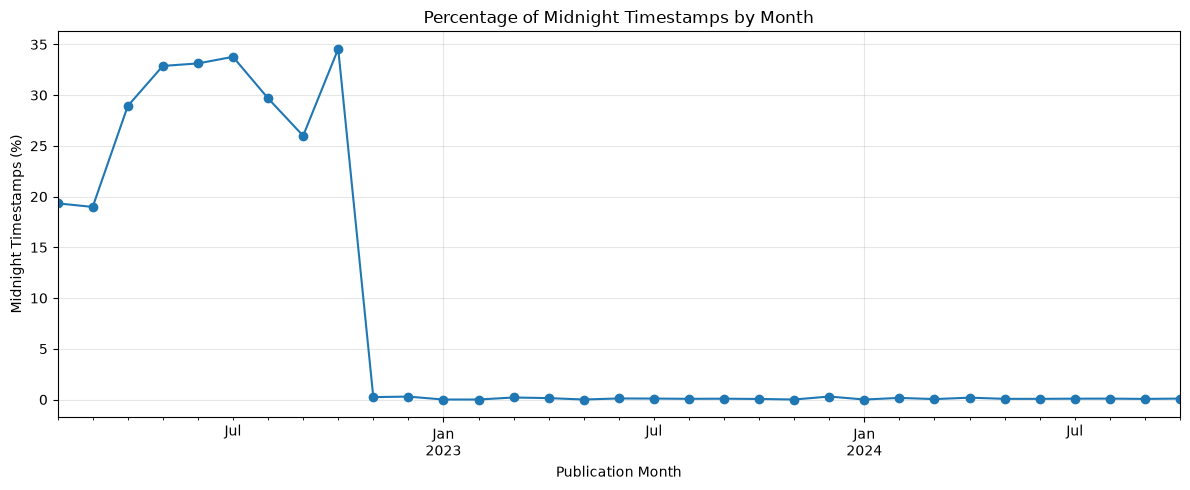

MONTHS WITH HIGHEST MIDNIGHT PERCENTAGE


timestamp
2022-10    34.558798
2022-07    33.772421
2022-06    33.123934
2022-05    32.877608
2022-08    29.683971
2022-04    28.926740
2022-09    25.991117
2022-02    19.334112
2022-03    18.978587
2023-12     0.295130
Freq: M, dtype: float64

In [52]:
import matplotlib.pyplot as plt

# Count midnight timestamps by publication month
midnight_by_month = (
    df_clean.loc[midnight_mask]
    .groupby(
        df_clean.loc[midnight_mask, "timestamp"]
        .dt.to_period("M")
    )
    .size()
)

# Count all Truths by publication month
truths_by_month = (
    df_clean.groupby(
        df_clean["timestamp"].dt.to_period("M")
    )
    .size()
)

# Percentage of midnight timestamps by month
midnight_percentage_by_month = (
    midnight_by_month
    .div(truths_by_month)
    .mul(100)
    .fillna(0)
)

plt.figure(figsize=(12, 5))

midnight_percentage_by_month.plot(
    kind="line",
    marker="o"
)

plt.title("Percentage of Midnight Timestamps by Month")
plt.xlabel("Publication Month")
plt.ylabel("Midnight Timestamps (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("MONTHS WITH HIGHEST MIDNIGHT PERCENTAGE")

display(
    midnight_percentage_by_month
    .sort_values(ascending=False)
    .head(10)
)

In [53]:

# Analyze Truths published after their scraping timestamp
future_scrape_records = df_clean.loc[
    future_scrape_mask,
    ["id", "timestamp", "time_scraped", "author"]
].copy()

# Calculate the time difference in hours
future_scrape_records["time_difference_hours"] = (
    future_scrape_records["timestamp"]
    - future_scrape_records["time_scraped"]
).dt.total_seconds() / 3600

print("TEMPORAL INCONSISTENCY ANALYSIS")
print("--------------------------------")
print(f"Inconsistent records: {len(future_scrape_records):,}")

print("\nTIME DIFFERENCE DISTRIBUTION (HOURS)")
display(
    future_scrape_records["time_difference_hours"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Classify inconsistencies by time difference
time_difference_bins = [0, 1, 6, 12, 24, 48, float("inf")]

time_difference_labels = [
    "0-1 hours",
    "1-6 hours",
    "6-12 hours",
    "12-24 hours",
    "24-48 hours",
    "More than 48 hours"
]

future_scrape_records["difference_category"] = pd.cut(
    future_scrape_records["time_difference_hours"],
    bins=time_difference_bins,
    labels=time_difference_labels,
    include_lowest=True
)

difference_distribution = (
    future_scrape_records["difference_category"]
    .value_counts(sort=False)
    .rename_axis("Time difference")
    .reset_index(name="Number of Truths")
)

difference_distribution["Percentage (%)"] = (
    difference_distribution["Number of Truths"]
    / len(future_scrape_records)
    * 100
).round(2)

print("\nTIME DIFFERENCE CATEGORIES")
display(difference_distribution)

print("\nSAMPLE INCONSISTENT RECORDS")
display(
    future_scrape_records.sort_values(
        "time_difference_hours",
        ascending=False
    ).head(10)
)


TEMPORAL INCONSISTENCY ANALYSIS
--------------------------------
Inconsistent records: 62,239

TIME DIFFERENCE DISTRIBUTION (HOURS)


count    62239.000000
mean         9.891684
std          7.059372
min          0.016667
25%          2.958333
50%         10.316667
75%         16.250000
90%         19.400000
95%         20.850000
99%         22.050000
max         23.900000
Name: time_difference_hours, dtype: float64


TIME DIFFERENCE CATEGORIES


,Time difference,Number of Truths,Percentage (%)
0,0-1 hours,5615,9.02
1,1-6 hours,20719,33.29
2,6-12 hours,7640,12.28
3,12-24 hours,28265,45.41
4,24-48 hours,0,0.00
5,More than 48 hours,0,0.00



SAMPLE INCONSISTENT RECORDS


,id,timestamp,time_scraped,author,time_difference_hours,difference_category
900776,1711111,2024-08-07 23:54:00,2024-08-07,475234,23.900000,12-24 hours
882667,1623909,2024-08-01 23:54:00,2024-08-01,454785,23.900000,12-24 hours
941589,1901285,2024-08-20 23:50:00,2024-08-20,417560,23.833333,12-24 hours
880017,1611548,2024-08-01 23:45:00,2024-08-01,455645,23.750000,12-24 hours
899503,1705888,2024-08-07 23:43:00,2024-08-07,198,23.716667,12-24 hours
833449,1399408,2024-07-15 23:40:00,2024-07-15,198893,23.666667,12-24 hours
880018,1611556,2024-08-01 23:40:00,2024-08-01,246730,23.666667,12-24 hours
880019,1611558,2024-08-01 23:39:00,2024-08-01,201754,23.650000,12-24 hours
833450,1399410,2024-07-15 23:38:00,2024-07-15,28,23.633333,12-24 hours
900874,1711538,2024-08-07 23:37:00,2024-08-07,472309,23.616667,12-24 hours


In [54]:

# Identify scraping timestamps recorded exactly at midnight
midnight_scrape_mask = (
    df_clean["time_scraped"].notna()
    & df_clean["time_scraped"].eq(
        df_clean["time_scraped"].dt.normalize()
    )
)

# Identify inconsistent records where scraping time is midnight
future_midnight_mask = future_scrape_mask & midnight_scrape_mask

# Check whether publication and scraping dates are identical
same_day_mask = (
    df_clean["timestamp"].notna()
    & df_clean["time_scraped"].notna()
    & df_clean["timestamp"].dt.normalize().eq(
        df_clean["time_scraped"].dt.normalize()
    )
)

future_same_day_mask = future_scrape_mask & same_day_mask

print("SCRAPING TIMESTAMP PRECISION ANALYSIS")
print("--------------------------------------")

print(
    "Scraping timestamps at midnight:",
    f"{midnight_scrape_mask.sum():,}"
)

print(
    "Percentage of all records:",
    f"{midnight_scrape_mask.mean() * 100:.2f}%"
)

print(
    "\nTemporal inconsistencies:",
    f"{future_scrape_mask.sum():,}"
)

print(
    "Inconsistencies with midnight scraping:",
    f"{future_midnight_mask.sum():,}"
)

print(
    "Inconsistencies within the same calendar day:",
    f"{future_same_day_mask.sum():,}"
)

print(
    "Inconsistencies NOT within the same calendar day:",
    f"{(future_scrape_mask & ~same_day_mask).sum():,}"
)

print(
    "\nInconsistencies with NON-midnight scraping:",
    f"{(future_scrape_mask & ~midnight_scrape_mask).sum():,}"
)

# Inspect exceptions to the midnight hypothesis
exceptions = df_clean.loc[
    future_scrape_mask & ~midnight_scrape_mask,
    ["id", "timestamp", "time_scraped", "author"]
]

print("\nSAMPLE EXCEPTIONS")
display(exceptions.head(10))


SCRAPING TIMESTAMP PRECISION ANALYSIS
--------------------------------------
Scraping timestamps at midnight: 277,911
Percentage of all records: 26.75%

Temporal inconsistencies: 62,239
Inconsistencies with midnight scraping: 62,239
Inconsistencies within the same calendar day: 62,239
Inconsistencies NOT within the same calendar day: 0

Inconsistencies with NON-midnight scraping: 0

SAMPLE EXCEPTIONS


,id,timestamp,time_scraped,author


In [56]:
import numpy as np
# Identify records with missing timestamps
missing_temporal_mask = (
    df_clean["timestamp"].isna()
    | df_clean["time_scraped"].isna()
)

# Classify the recorded scraping timestamp
df_clean["scraping_time_precision"] = np.select(
    [
        df_clean["time_scraped"].isna(),
        midnight_scrape_mask
    ],
    [
        "missing",
        "date_only_candidate"
    ],
    default="datetime_recorded"
)

# Classify temporal consistency
df_clean["temporal_quality_status"] = np.select(
    [
        missing_temporal_mask,
        future_scrape_mask & midnight_scrape_mask & same_day_mask,
        future_scrape_mask
    ],
    [
        "missing_timestamp",
        "same_day_midnight_ambiguity",
        "chronological_inconsistency"
    ],
    default="chronologically_consistent"
)

print("SCRAPING TIME PRECISION")
display(
    df_clean["scraping_time_precision"]
    .value_counts(dropna=False)
    .to_frame("Number of Truths")
)

print("\nTEMPORAL QUALITY STATUS")
display(
    df_clean["temporal_quality_status"]
    .value_counts(dropna=False)
    .to_frame("Number of Truths")
)

# Validate the classification
assert (
    df_clean["temporal_quality_status"]
    .eq("same_day_midnight_ambiguity")
    .sum()
    == 62239
)

assert (
    df_clean["temporal_quality_status"]
    .eq("chronological_inconsistency")
    .sum()
    == 0
)

print("\nTemporal classification completed successfully.")


SCRAPING TIME PRECISION


,Number of Truths
scraping_time_precision,
datetime_recorded,760910
date_only_candidate,277911



TEMPORAL QUALITY STATUS


,Number of Truths
temporal_quality_status,
chronologically_consistent,976582
same_day_midnight_ambiguity,62239



Temporal classification completed successfully.


In [57]:

# Analyze publication and scraping date ranges
print("PUBLICATION DATE PLAUSIBILITY ANALYSIS")
print("--------------------------------------")

print("Earliest publication:", df_clean["timestamp"].min())
print("Latest publication:", df_clean["timestamp"].max())

print("\nEarliest scraping:", df_clean["time_scraped"].min())
print("Latest scraping:", df_clean["time_scraped"].max())

# Count publications by year
publication_years = (
    df_clean["timestamp"]
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Year")
    .reset_index(name="Number of Truths")
)

print("\nPUBLICATIONS BY YEAR")
display(publication_years)

# Flag publication dates before the platform's launch year
pre_2022_mask = (
    df_clean["timestamp"].notna()
    & (df_clean["timestamp"].dt.year < 2022)
)

print("\nPOSTS BEFORE 2022:", f"{pre_2022_mask.sum():,}")

display(
    df_clean.loc[
        pre_2022_mask,
        ["id", "timestamp", "time_scraped", "author"]
    ].head(10)
)

# Compare publication and scraping calendar dates
different_day_future_mask = (
    df_clean["timestamp"].notna()
    & df_clean["time_scraped"].notna()
    & (
        df_clean["timestamp"].dt.normalize()
        > df_clean["time_scraped"].dt.normalize()
    )
)

print(
    "\nPUBLICATION DATE AFTER SCRAPING DATE:",
    f"{different_day_future_mask.sum():,}"
)


PUBLICATION DATE PLAUSIBILITY ANALYSIS
--------------------------------------
Earliest publication: 2022-02-07 23:31:00
Latest publication: 2024-10-29 21:24:00

Earliest scraping: 2022-09-14 17:27:42.677694
Latest scraping: 2024-10-29 00:00:00

PUBLICATIONS BY YEAR


,Year,Number of Truths
0,2022,765709
1,2023,13960
2,2024,259152



POSTS BEFORE 2022: 0


,id,timestamp,time_scraped,author



PUBLICATION DATE AFTER SCRAPING DATE: 0


## Final Checks and Export of the clean dataset

In [58]:

# Final structural and data quality validation
print("FINAL DATA QUALITY VALIDATION")
print("-" * 40)

print(f"Total records: {len(df_clean):,}")
print(f"Total columns: {df_clean.shape[1]}")

# Primary key validation
print("\nPRIMARY KEY VALIDATION")
print("Missing IDs:", df_clean["id"].isna().sum())
print("Duplicated IDs:", df_clean["id"].duplicated().sum())
print("Unique IDs:", df_clean["id"].nunique())

# Missing values in essential attributes
essential_columns = [
    "id",
    "timestamp",
    "time_scraped",
    "author",
    "external_id"
]

print("\nMISSING VALUES IN ESSENTIAL COLUMNS")
display(
    df_clean[essential_columns]
    .isna()
    .sum()
    .to_frame("Missing values")
)

# Check invalid negative values in numerical columns
count_columns = [
    "like_count",
    "retruth_count",
    "reply_count"
]

print("\nNEGATIVE ENGAGEMENT COUNTS")
negative_counts = (
    df_clean[count_columns]
    .lt(0)
    .sum()
    .to_frame("Negative values")
)

display(negative_counts)

# Validate primary key
assert df_clean["id"].notna().all(), "Missing primary keys detected"
assert df_clean["id"].is_unique, "Duplicated primary keys detected"

print("\nPrimary key validation passed.")


FINAL DATA QUALITY VALIDATION
----------------------------------------
Total records: 1,038,821
Total columns: 27

PRIMARY KEY VALIDATION
Missing IDs: 0
Duplicated IDs: 0
Unique IDs: 1038821

MISSING VALUES IN ESSENTIAL COLUMNS


,Missing values
id,0
timestamp,0
time_scraped,0
author,0
external_id,0



NEGATIVE ENGAGEMENT COUNTS


,Negative values
like_count,0
retruth_count,0
reply_count,0



Primary key validation passed.


In [59]:

import pandas as pd

print("EXTERNAL IDENTIFIERS AND URL VALIDATION")
print("-" * 45)

# Normalize external IDs as strings for validation
external_ids = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
)

# Check whether external IDs are numeric
valid_external_id_mask = external_ids.str.fullmatch(r"\d+").fillna(False)

print("Invalid external IDs:",
      f"{(~valid_external_id_mask).sum():,}")

# Convert URLs to strings for structural checks
urls = df_clean["url"].astype("string").str.strip()

# Extract the post ID from the URL
url_external_ids = urls.str.extract(
    r"^https?://truthsocial\.com/@[^/]+/posts/(\d+)/?$",
    expand=False
)

# Check URL structure
valid_url_mask = url_external_ids.notna()

print("Invalid URL structures:",
      f"{(~valid_url_mask).sum():,}")

# Compare external IDs with IDs extracted from URLs
comparable_mask = valid_external_id_mask & valid_url_mask

mismatch_mask = (
    comparable_mask
    & external_ids.ne(url_external_ids).fillna(False)
)

print("Comparable records:",
      f"{comparable_mask.sum():,}")

print("External ID / URL mismatches:",
      f"{mismatch_mask.sum():,}")

# Display problematic examples
print("\nSAMPLE INVALID URLS")
display(
    df_clean.loc[
        ~valid_url_mask,
        ["id", "external_id", "url", "author"]
    ].head(10)
)

print("\nSAMPLE ID / URL MISMATCHES")
display(
    df_clean.loc[
        mismatch_mask,
        ["id", "external_id", "url", "author"]
    ].head(10)
)


EXTERNAL IDENTIFIERS AND URL VALIDATION
---------------------------------------------
Invalid external IDs: 17,577
Invalid URL structures: 17,624
Comparable records: 1,021,197
External ID / URL mismatches: 0

SAMPLE INVALID URLS


,id,external_id,url,author
1165,807653,CeceBloomwood,107949547160373982,20054
1166,807654,CeceBloomwood,107945338731779453,20054
1167,807655,CeceBloomwood,107925568586381393,20054
1168,807656,CeceBloomwood,107914242452173533,20054
1169,807657,CeceBloomwood,107912178895243526,20054
1170,704521,PadingtonRose,108451075405955467,11225
1171,704523,PadingtonRose,108451037257647019,11225
1172,704539,Cmac67,108420053177728792,2335
1173,704540,PadingtonRose,108450814142383247,11225
1174,704542,PadingtonRose,108448432916302198,11225



SAMPLE ID / URL MISMATCHES


,id,external_id,url,author


In [60]:

# Classify external ID and URL anomalies
invalid_external_mask = ~valid_external_id_mask
invalid_url_mask = ~valid_url_mask

# Identify overlapping anomalies
both_invalid_mask = invalid_external_mask & invalid_url_mask
only_external_invalid_mask = invalid_external_mask & ~invalid_url_mask
only_url_invalid_mask = ~invalid_external_mask & invalid_url_mask

# Detect numeric values stored in the URL column
numeric_url_mask = urls.str.fullmatch(r"\d+").fillna(False)

# Detect username-like values in external_id
username_like_mask = external_ids.str.fullmatch(
    r"[A-Za-z0-9_]+"
).fillna(False) & invalid_external_mask

# Potential shifted-column pattern
shifted_pattern_mask = (
    both_invalid_mask
    & numeric_url_mask
    & username_like_mask
)

print("EXTERNAL ID / URL ANOMALY CLASSIFICATION")
print("-" * 45)

print("Both fields invalid:", f"{both_invalid_mask.sum():,}")
print(
    "Only external_id invalid:",
    f"{only_external_invalid_mask.sum():,}"
)
print(
    "Only URL invalid:",
    f"{only_url_invalid_mask.sum():,}"
)

print("\nPOTENTIAL COLUMN MISALIGNMENT")
print(
    "Invalid URLs containing numeric IDs:",
    f"{(invalid_url_mask & numeric_url_mask).sum():,}"
)
print(
    "Username-like external IDs:",
    f"{username_like_mask.sum():,}"
)
print(
    "Records matching shifted-column pattern:",
    f"{shifted_pattern_mask.sum():,}"
)

print("\nSAMPLE POTENTIALLY SHIFTED RECORDS")
display(
    df_clean.loc[
        shifted_pattern_mask,
        ["id", "external_id", "url", "author"]
    ].head(10)
)

print("\nOTHER INVALID URL PATTERNS")
display(
    df_clean.loc[
        invalid_url_mask & ~shifted_pattern_mask,
        ["id", "external_id", "url", "author"]
    ].head(15)
)


EXTERNAL ID / URL ANOMALY CLASSIFICATION
---------------------------------------------
Both fields invalid: 17,577
Only external_id invalid: 0
Only URL invalid: 47

POTENTIAL COLUMN MISALIGNMENT
Invalid URLs containing numeric IDs: 17,623
Username-like external IDs: 17,576
Records matching shifted-column pattern: 17,576

SAMPLE POTENTIALLY SHIFTED RECORDS


,id,external_id,url,author
1165,807653,CeceBloomwood,107949547160373982,20054
1166,807654,CeceBloomwood,107945338731779453,20054
1167,807655,CeceBloomwood,107925568586381393,20054
1168,807656,CeceBloomwood,107914242452173533,20054
1169,807657,CeceBloomwood,107912178895243526,20054
1170,704521,PadingtonRose,108451075405955467,11225
1171,704523,PadingtonRose,108451037257647019,11225
1172,704539,Cmac67,108420053177728792,2335
1173,704540,PadingtonRose,108450814142383247,11225
1174,704542,PadingtonRose,108448432916302198,11225



OTHER INVALID URL PATTERNS


,id,external_id,url,author
295192,130246,1244,108966175235482499,2923
295194,130250,1244,108966165367872509,2923
295196,130257,1244,108966160218011559,2923
295200,130273,1244,108966082767451419,2923
295203,130278,1244,108966050533705549,2923
295204,130282,1244,108966048268961756,2923
295207,130291,1244,108965992596639782,2923
295211,130308,1244,108965924539626020,2923
295212,130312,1244,108965905866640711,2923
295213,130317,1244,108965899842016041,2923


In [61]:

# Analyze the three anomaly groups separately
group_a = df_clean.loc[
    shifted_pattern_mask,
    ["id", "external_id", "url", "author"]
].copy()

group_b = df_clean.loc[
    both_invalid_mask & ~shifted_pattern_mask,
    ["id", "external_id", "url", "author"]
].copy()

group_c = df_clean.loc[
    only_url_invalid_mask,
    ["id", "external_id", "url", "author"]
].copy()

print("ANOMALY GROUP ANALYSIS")
print("-" * 40)

print(f"Group A - username / numeric URL: {len(group_a):,}")
print(f"Group B - other double-invalid patterns: {len(group_b):,}")
print(f"Group C - numeric external_id / numeric URL: {len(group_c):,}")

# Compare numeric URLs with external IDs already present
known_external_ids = set(
    external_ids.loc[valid_external_id_mask]
)

group_a["numeric_url_known"] = (
    group_a["url"].astype("string").isin(known_external_ids)
)

group_c["numeric_url_known"] = (
    group_c["url"].astype("string").isin(known_external_ids)
)

print("\nNUMERIC URL MATCHES WITH EXISTING EXTERNAL IDs")
print("Group A:", group_a["numeric_url_known"].sum())
print("Group C:", group_c["numeric_url_known"].sum())

print("\nGROUP B - EXCEPTIONAL RECORD")
display(group_b)

print("\nGROUP C - ALL RECORDS")
display(group_c)

print("\nGROUP A - SAMPLE")
display(group_a.head(10))


ANOMALY GROUP ANALYSIS
----------------------------------------
Group A - username / numeric URL: 17,576
Group B - other double-invalid patterns: 1
Group C - numeric external_id / numeric URL: 47

NUMERIC URL MATCHES WITH EXISTING EXTERNAL IDs
Group A: 279
Group C: 0

GROUP B - EXCEPTIONAL RECORD


,id,external_id,url,author
519946,430702,2022-03-07 07:16:00,2022-10-14 22:35:25.809822,9375



GROUP C - ALL RECORDS


,id,external_id,url,author,numeric_url_known
295192,130246,1244,108966175235482499,2923,False
295194,130250,1244,108966165367872509,2923,False
295196,130257,1244,108966160218011559,2923,False
295200,130273,1244,108966082767451419,2923,False
295203,130278,1244,108966050533705549,2923,False
295204,130282,1244,108966048268961756,2923,False
295207,130291,1244,108965992596639782,2923,False
295211,130308,1244,108965924539626020,2923,False
295212,130312,1244,108965905866640711,2923,False
295213,130317,1244,108965899842016041,2923,False



GROUP A - SAMPLE


,id,external_id,url,author,numeric_url_known
1165,807653,CeceBloomwood,107949547160373982,20054,False
1166,807654,CeceBloomwood,107945338731779453,20054,False
1167,807655,CeceBloomwood,107925568586381393,20054,False
1168,807656,CeceBloomwood,107914242452173533,20054,False
1169,807657,CeceBloomwood,107912178895243526,20054,False
1170,704521,PadingtonRose,108451075405955467,11225,False
1171,704523,PadingtonRose,108451037257647019,11225,False
1172,704539,Cmac67,108420053177728792,2335,False
1173,704540,PadingtonRose,108450814142383247,11225,False
1174,704542,PadingtonRose,108448432916302198,11225,False


In [62]:

# Build a reference mapping using valid Truth URLs
valid_truths = df_clean.loc[
    valid_url_mask,
    ["id", "author", "external_id", "url"]
].copy()

valid_truths["url_username"] = (
    valid_truths["url"]
    .astype("string")
    .str.extract(r"truthsocial\.com/@([^/]+)/posts/", expand=False)
)

# Collect known usernames associated with each author
author_usernames = (
    valid_truths.dropna(subset=["author", "url_username"])
    .groupby("author")["url_username"]
    .agg(lambda values: set(values))
    .to_dict()
)

# Check whether the suspected username matches a known username
group_a["username_matches_author"] = group_a.apply(
    lambda row: (
        row["external_id"] in author_usernames[row["author"]]
        if row["author"] in author_usernames
        else pd.NA
    ),
    axis=1
)

print("GROUP A - USERNAME VALIDATION")
print("-" * 45)

display(
    group_a["username_matches_author"]
    .astype("string")
    .fillna("No reference")
    .value_counts()
    .to_frame("Number of Truths")
)

# Check collisions between candidate recovered IDs and valid IDs
existing_ids = valid_truths[
    ["id", "author", "external_id"]
].copy()

existing_ids["external_id"] = (
    existing_ids["external_id"].astype("string").str.strip()
)

collisions = group_a.merge(
    existing_ids,
    left_on="url",
    right_on="external_id",
    how="inner",
    suffixes=("_anomalous", "_existing")
)

print("\nEXTERNAL ID COLLISION ANALYSIS")
print("-" * 45)

print("Collision pairs:", f"{len(collisions):,}")
print(
    "Distinct anomalous records involved:",
    f"{collisions['id_anomalous'].nunique():,}"
)

print("\nSAMPLE COLLISIONS")
display(collisions.head(10))

# Inspect all fields of the exceptional record
print("\nGROUP B - COMPLETE RECORD")
display(
    df_clean.loc[
        df_clean["id"].eq(430702)
    ].T
)

# Investigate the constant value in Group C
print("\nGROUP C - EXTERNAL ID VALUES")
display(group_c["external_id"].value_counts())

print("\nGROUP C - AUTHORS")
display(group_c["author"].value_counts())


GROUP A - USERNAME VALIDATION
---------------------------------------------


,Number of Truths
username_matches_author,
True,16947
No reference,628
False,1



EXTERNAL ID COLLISION ANALYSIS
---------------------------------------------
Collision pairs: 279
Distinct anomalous records involved: 279

SAMPLE COLLISIONS


,id_anomalous,external_id_anomalous,url,author_anomalous,numeric_url_known,username_matches_author,id_existing,author_existing,external_id_existing
0,818451,WallStreetApes,109125020942159323,498,True,True,1679803,498,109125020942159323
1,851191,Kash,109113486460619152,174,True,True,752349,174,109113486460619152
2,818785,WallStreetApes,109011584962681556,498,True,True,1680038,498,109011584962681556
3,829423,TheRedPillNews,108898274009744580,514,True,True,1518754,514,108898274009744580
4,883573,golfclap,108589638178438928,888,True,True,36833,888,108589638178438928
5,883575,golfclap,108233165099876796,888,True,True,36839,888,108233165099876796
6,883578,golfclap,108035229415129820,888,True,True,36843,888,108035229415129820
7,883580,golfclap,107978506986678400,888,True,True,36845,888,107978506986678400
8,883582,golfclap,107966718840483467,888,True,True,36846,888,107966718840483467
9,883584,golfclap,107910894556763914,888,True,True,36850,888,107910894556763914



GROUP B - COMPLETE RECORD


,519946
id,430702
timestamp,2022-03-15 05:47:00
time_scraped,2022-10-14 22:34:56.932013
is_retruth,False
is_reply,False
author,9375
like_count,0
retruth_count,0
reply_count,0
text,"""“Ming/Putin” (Klytus/Biden) I''m bored. What ..."



GROUP C - EXTERNAL ID VALUES


external_id
1244    47
Name: count, dtype: Int64


GROUP C - AUTHORS


author
2923    47
Name: count, dtype: Int64

In [63]:

# Investigate external ID collisions more thoroughly

collision_ids = collisions["id_anomalous"].unique()

anomalous_collisions = df_clean.loc[
    df_clean["id"].isin(collision_ids),
    ["id", "timestamp", "author", "text"]
].rename(
    columns={
        "id": "id_anomalous",
        "timestamp": "timestamp_anomalous",
        "author": "author_anomalous_check",
        "text": "text_anomalous"
    }
)

existing_collision_ids = collisions["id_existing"].unique()

existing_collisions = df_clean.loc[
    df_clean["id"].isin(existing_collision_ids),
    ["id", "timestamp", "author", "text"]
].rename(
    columns={
        "id": "id_existing",
        "timestamp": "timestamp_existing",
        "author": "author_existing_check",
        "text": "text_existing"
    }
)

collision_comparison = (
    collisions
    .merge(anomalous_collisions, on="id_anomalous", how="left")
    .merge(existing_collisions, on="id_existing", how="left")
)

collision_comparison["same_author"] = (
    collision_comparison["author_anomalous"]
    == collision_comparison["author_existing"]
)

collision_comparison["same_timestamp"] = (
    collision_comparison["timestamp_anomalous"]
    == collision_comparison["timestamp_existing"]
)

collision_comparison["same_text"] = (
    collision_comparison["text_anomalous"].fillna("")
    == collision_comparison["text_existing"].fillna("")
)

print("COLLISION CONSISTENCY ANALYSIS")
print("-" * 45)

for column in ["same_author", "same_timestamp", "same_text"]:
    print(f"\n{column}")
    print(collision_comparison[column].value_counts(dropna=False))

print("\nSAMPLE CONFLICTING COLLISIONS")
display(
    collision_comparison.loc[
        ~(
            collision_comparison["same_author"]
            & collision_comparison["same_timestamp"]
            & collision_comparison["same_text"]
        ),
        [
            "id_anomalous",
            "id_existing",
            "same_author",
            "same_timestamp",
            "same_text",
            "timestamp_anomalous",
            "timestamp_existing"
        ]
    ].head(15)
)

# Inspect group A cases without an author reference
no_reference_group_a = group_a.loc[
    group_a["username_matches_author"].isna()
].copy()

print("\nGROUP A - NO REFERENCE")
print("Records:", len(no_reference_group_a))
print("Distinct authors:", no_reference_group_a["author"].nunique())
display(no_reference_group_a.head(10))

# Inspect the username mismatch
print("\nGROUP A - USERNAME MISMATCH")
display(
    group_a.loc[
        group_a["username_matches_author"].eq(False).fillna(False)
    ]
)

# Investigate the author of Group C
print("\nGROUP C - AUTHOR USERNAME REFERENCES")

group_c_author = group_c["author"].iloc[0]

print("Author ID:", group_c_author)
print(
    "Known usernames:",
    author_usernames.get(group_c_author, "No reference available")
)


COLLISION CONSISTENCY ANALYSIS
---------------------------------------------

same_author
same_author
True     268
False     11
Name: count, dtype: Int64

same_timestamp
same_timestamp
False    268
True      11
Name: count, dtype: int64

same_text
same_text
True     257
False     22
Name: count, dtype: Int64

SAMPLE CONFLICTING COLLISIONS


,id_anomalous,id_existing,same_author,same_timestamp,same_text,timestamp_anomalous,timestamp_existing
0,818451,1679803,True,False,True,2022-10-07,2022-10-07 04:07:00
1,851191,752349,True,True,False,2022-10-04,2022-10-04 00:00:00
2,818785,1680038,True,False,True,2022-09-16,2022-09-17 03:19:00
3,829423,1518754,True,False,False,2022-08-27,2022-08-28 03:03:00
4,883573,36833,True,False,True,2022-07-04,2022-07-04 10:53:00
5,883575,36839,True,False,True,2022-05-02,2022-05-02 11:57:00
6,883578,36843,True,False,True,2022-03-28,2022-03-28 12:59:00
7,883580,36845,True,False,True,2022-03-18,2022-03-18 12:34:00
8,883582,36846,True,False,True,2022-03-16,2022-03-16 10:36:00
9,883584,36850,True,False,True,2022-03-06,2022-03-06 12:59:00



GROUP A - NO REFERENCE
Records: 628
Distinct authors: 110


,id,external_id,url,author,numeric_url_known,username_matches_author
19050,723113,MarieYarger,109088327488770457,17778,False,<NA>
19051,723114,MarieYarger,109044375155090322,17778,False,<NA>
19052,723115,MarieYarger,109044370082097330,17778,False,<NA>
19053,723116,MarieYarger,108960711056821442,17778,False,<NA>
19054,723117,MarieYarger,108949238054196798,17778,False,<NA>
19055,723118,MarieYarger,108891911730434904,17778,False,<NA>
19056,723119,MarieYarger,108844889312650531,17778,False,<NA>
19057,723120,MarieYarger,108827263250972637,17778,False,<NA>
19058,723121,MarieYarger,108806332392383458,17778,False,<NA>
19059,723122,MarieYarger,108804813852686518,17778,False,<NA>



GROUP A - USERNAME MISMATCH


,id,external_id,url,author,numeric_url_known,username_matches_author
134233,894769,JackPosobiec,107947130681947614,21203,True,False



GROUP C - AUTHOR USERNAME REFERENCES
Author ID: 2923
Known usernames: {'1244'}


In [64]:

# Compare publication dates instead of exact timestamps
collision_comparison["same_publication_date"] = (
    collision_comparison["timestamp_anomalous"].dt.normalize()
    == collision_comparison["timestamp_existing"].dt.normalize()
)

# Identify midnight publication timestamps
collision_comparison["anomalous_midnight"] = (
    collision_comparison["timestamp_anomalous"]
    == collision_comparison["timestamp_anomalous"].dt.normalize()
)

collision_comparison["existing_midnight"] = (
    collision_comparison["timestamp_existing"]
    == collision_comparison["timestamp_existing"].dt.normalize()
)

# Flag potential logical duplicates
collision_comparison["potential_logical_duplicate"] = (
    collision_comparison["same_author"]
    & collision_comparison["same_text"]
    & collision_comparison["same_publication_date"]
)

print("LOGICAL DUPLICATE ANALYSIS")
print("-" * 45)

print("Total collision pairs:", len(collision_comparison))

print(
    "Same publication date:",
    collision_comparison["same_publication_date"].sum()
)

print(
    "Anomalous timestamp at midnight:",
    collision_comparison["anomalous_midnight"].sum()
)

print(
    "Existing timestamp at midnight:",
    collision_comparison["existing_midnight"].sum()
)

print(
    "\nPotential logical duplicates:",
    collision_comparison["potential_logical_duplicate"].sum()
)

print(
    "Remaining conflicting pairs:",
    (~collision_comparison["potential_logical_duplicate"]).sum()
)

# Inspect remaining conflicts
conflicting_pairs = collision_comparison.loc[
    ~collision_comparison["potential_logical_duplicate"]
].copy()

print("\nCONFLICT CLASSIFICATION")
display(
    conflicting_pairs[
        ["same_author", "same_text", "same_publication_date"]
    ]
    .value_counts(dropna=False)
    .to_frame("Number of pairs")
)

print("\nSAMPLE CONFLICTING PAIRS")
display(
    conflicting_pairs[
        [
            "id_anomalous",
            "id_existing",
            "same_author",
            "same_text",
            "same_publication_date",
            "timestamp_anomalous",
            "timestamp_existing"
        ]
    ].head(20)
)


LOGICAL DUPLICATE ANALYSIS
---------------------------------------------
Total collision pairs: 279
Same publication date: 277
Anomalous timestamp at midnight: 275
Existing timestamp at midnight: 15

Potential logical duplicates: 247
Remaining conflicting pairs: 32

CONFLICT CLASSIFICATION


Number of pairs
same_author same_text same_publication_date                 
True        False     True                                19
False       True      True                                 9
            False     True                                 2
True        True      False                                1
            False     False                                1


SAMPLE CONFLICTING PAIRS


,id_anomalous,id_existing,same_author,same_text,same_publication_date,timestamp_anomalous,timestamp_existing
1,851191,752349,True,False,True,2022-10-04,2022-10-04 00:00:00
2,818785,1680038,True,True,False,2022-09-16,2022-09-17 03:19:00
3,829423,1518754,True,False,False,2022-08-27,2022-08-28 03:03:00
17,884491,83656,True,False,True,2022-08-27,2022-08-27 11:13:00
20,884494,83662,True,False,True,2022-08-23,2022-08-23 11:38:00
23,884497,83665,True,False,True,2022-08-22,2022-08-22 12:44:00
27,884501,83669,True,False,True,2022-08-19,2022-08-19 10:32:00
28,884502,83671,True,False,True,2022-08-18,2022-08-18 11:04:00
31,884504,83676,True,False,True,2022-08-12,2022-08-12 10:36:00
32,894769,894768,True,False,True,2022-03-12,2022-03-12 00:00:00


In [65]:

# Select potential logical duplicate pairs
logical_duplicates = collision_comparison.loc[
    collision_comparison["potential_logical_duplicate"]
].copy()

# Attributes to compare
comparison_columns = [
    "id",
    "like_count",
    "retruth_count",
    "reply_count",
    "is_retruth",
    "is_reply",
    "time_scraped"
]

# Retrieve attributes for anomalous records
anomalous_details = df_clean[comparison_columns].rename(
    columns={
        col: f"{col}_anomalous"
        for col in comparison_columns
        if col != "id"
    }
).rename(columns={"id": "id_anomalous"})

# Retrieve attributes for existing records
existing_details = df_clean[comparison_columns].rename(
    columns={
        col: f"{col}_existing"
        for col in comparison_columns
        if col != "id"
    }
).rename(columns={"id": "id_existing"})

# Merge details into the collision comparison
duplicate_details = (
    logical_duplicates
    .merge(anomalous_details, on="id_anomalous", how="left")
    .merge(existing_details, on="id_existing", how="left")
)

# Compare each attribute
attributes_to_check = [
    "like_count",
    "retruth_count",
    "reply_count",
    "is_retruth",
    "is_reply",
    "time_scraped"
]

for col in attributes_to_check:
    duplicate_details[f"same_{col}"] = (
        duplicate_details[f"{col}_anomalous"]
        .eq(duplicate_details[f"{col}_existing"])
        .fillna(False)
    )

print("POTENTIAL DUPLICATE ATTRIBUTE COMPARISON")
print("-" * 45)

for col in attributes_to_check:
    matching = duplicate_details[f"same_{col}"].sum()

    print(
        f"{col}: {matching:,} / {len(duplicate_details):,} "
        f"matching pairs"
    )

# Count pairs with identical checked attributes
comparison_flags = [
    f"same_{col}"
    for col in attributes_to_check
]

duplicate_details["all_checked_attributes_match"] = (
    duplicate_details[comparison_flags].all(axis=1)
)

print(
    "\nPairs with all checked attributes matching:",
    duplicate_details["all_checked_attributes_match"].sum()
)

print("\nSAMPLE PAIRS WITH DIFFERENT ENGAGEMENT")
engagement_columns = [
    "same_like_count",
    "same_retruth_count",
    "same_reply_count"
]

different_engagement_mask = ~duplicate_details[
    engagement_columns
].all(axis=1)

display(
    duplicate_details.loc[
        different_engagement_mask,
        [
            "id_anomalous",
            "id_existing",
            "like_count_anomalous",
            "like_count_existing",
            "retruth_count_anomalous",
            "retruth_count_existing",
            "reply_count_anomalous",
            "reply_count_existing",
            "time_scraped_anomalous",
            "time_scraped_existing"
        ]
    ].head(15)
)


POTENTIAL DUPLICATE ATTRIBUTE COMPARISON
---------------------------------------------
like_count: 239 / 247 matching pairs
retruth_count: 243 / 247 matching pairs
reply_count: 243 / 247 matching pairs
is_retruth: 247 / 247 matching pairs
is_reply: 247 / 247 matching pairs
time_scraped: 0 / 247 matching pairs

Pairs with all checked attributes matching: 0

SAMPLE PAIRS WITH DIFFERENT ENGAGEMENT


,id_anomalous,id_existing,like_count_anomalous,like_count_existing,retruth_count_anomalous,retruth_count_existing,reply_count_anomalous,reply_count_existing,time_scraped_anomalous,time_scraped_existing
0,818451,1679803,33,32,17,17,2,1,2022-11-26 08:24:51.757687,2024-08-05 00:00:00.000000
1,883573,36833,3,1,0,0,1,1,2022-12-08 10:26:51.387867,2022-09-18 03:07:31.170996
9,884485,83639,3,0,1,0,1,0,2022-12-08 11:20:59.714091,2022-09-23 18:04:59.395423
17,884496,83664,1,1,0,1,1,1,2022-12-08 11:21:42.085331,2022-09-23 18:05:29.031553
23,897728,337690,165,165,59,62,14,13,2022-12-09 12:33:31.586299,2022-10-09 09:14:47.928435
46,914193,91372,2,3,0,0,0,0,2022-12-10 20:36:49.428619,2022-09-26 01:30:26.528400
88,914244,91580,1,2,0,0,0,0,2022-12-10 20:41:25.435167,2022-09-26 01:34:42.868665
243,31863,931439,36,37,7,7,4,4,2022-09-17 17:06:56.364527,2022-12-11 15:15:20.381276
245,337476,746740,802,800,398,398,54,54,2022-10-09 09:12:44.105018,2022-11-10 01:45:53.852457
246,338248,746778,4307,0,1333,0,187,0,2022-10-09 09:19:57.105922,2022-11-10 01:58:08.355131


In [66]:

# Candidate external IDs stored in numeric URL fields
recoverable_candidates = df_clean.loc[
    numeric_url_mask & invalid_url_mask,
    ["id", "author", "external_id", "url"]
].copy()

recoverable_candidates["candidate_external_id"] = (
    recoverable_candidates["url"]
    .astype("string")
    .str.strip()
)

# Check duplicates among recovered candidate IDs
duplicate_candidate_mask = (
    recoverable_candidates["candidate_external_id"]
    .duplicated(keep=False)
)

# Identify candidate IDs already present in valid records
valid_external_ids_set = set(
    external_ids.loc[valid_external_id_mask & valid_url_mask]
)

recoverable_candidates["collides_with_valid_record"] = (
    recoverable_candidates["candidate_external_id"]
    .isin(valid_external_ids_set)
)

# Classify recovery candidates
recoverable_candidates["recovery_status"] = np.select(
    [
        duplicate_candidate_mask,
        recoverable_candidates["collides_with_valid_record"]
    ],
    [
        "duplicate_candidate_id",
        "collision_with_existing_record"
    ],
    default="unique_candidate"
)

print("EXTERNAL ID RECOVERY CANDIDATE ANALYSIS")
print("-" * 45)

print(
    "Total recovery candidates:",
    f"{len(recoverable_candidates):,}"
)

print(
    "Distinct candidate external IDs:",
    f"{recoverable_candidates['candidate_external_id'].nunique():,}"
)

print(
    "Candidates duplicated within anomalous records:",
    f"{duplicate_candidate_mask.sum():,}"
)

print("\nRECOVERY STATUS")
display(
    recoverable_candidates["recovery_status"]
    .value_counts()
    .to_frame("Number of Truths")
)

print("\nSAMPLE DUPLICATE CANDIDATES")
display(
    recoverable_candidates.loc[
        duplicate_candidate_mask
    ].head(15)
)

print("\nSAMPLE COLLISIONS")
display(
    recoverable_candidates.loc[
        recoverable_candidates["collides_with_valid_record"]
    ].head(10)
)


EXTERNAL ID RECOVERY CANDIDATE ANALYSIS
---------------------------------------------
Total recovery candidates: 17,623
Distinct candidate external IDs: 17,458
Candidates duplicated within anomalous records: 330

RECOVERY STATUS


,Number of Truths
recovery_status,
unique_candidate,17022
duplicate_candidate_id,330
collision_with_existing_record,271



SAMPLE DUPLICATE CANDIDATES


,id,author,external_id,url,candidate_external_id,collides_with_valid_record,recovery_status
134639,895511,11214,truthtent,108864982160272342,108864982160272342,False,duplicate_candidate_id
134640,895509,21179,TootieBird,108864982160272342,108864982160272342,False,duplicate_candidate_id
134654,895527,143,JackPosobiec,108822381542261053,108822381542261053,False,duplicate_candidate_id
134655,895526,21179,TootieBird,108822381542261053,108822381542261053,False,duplicate_candidate_id
134658,895534,27,realDonaldTrump,109073924301696705,109073924301696705,False,duplicate_candidate_id
134663,895535,2098,JohnPaulMacIsaac,108814846897812544,108814846897812544,False,duplicate_candidate_id
134664,895536,933,Lara45,109073924301696705,109073924301696705,False,duplicate_candidate_id
134665,895533,21179,TootieBird,108814846897812544,108814846897812544,False,duplicate_candidate_id
134672,895593,27,realDonaldTrump,109017355982286163,109017355982286163,False,duplicate_candidate_id
134683,895587,559,MelaniaTrump,109027164115408705,109027164115408705,False,duplicate_candidate_id



SAMPLE COLLISIONS


,id,author,external_id,url,candidate_external_id,collides_with_valid_record,recovery_status
80744,818451,498,WallStreetApes,109125020942159323,109125020942159323,True,collision_with_existing_record
83499,851191,174,Kash,109113486460619152,109113486460619152,True,collision_with_existing_record
83550,818785,498,WallStreetApes,109011584962681556,109011584962681556,True,collision_with_existing_record
93082,829423,514,TheRedPillNews,108898274009744580,108898274009744580,True,collision_with_existing_record
127620,883573,888,golfclap,108589638178438928,108589638178438928,True,collision_with_existing_record
127622,883575,888,golfclap,108233165099876796,108233165099876796,True,collision_with_existing_record
127625,883578,888,golfclap,108035229415129820,108035229415129820,True,collision_with_existing_record
127627,883580,888,golfclap,107978506986678400,107978506986678400,True,collision_with_existing_record
127629,883582,888,golfclap,107966718840483467,107966718840483467,True,collision_with_existing_record
127631,883584,888,golfclap,107910894556763914,107910894556763914,True,collision_with_existing_record


In [67]:

# Recover validated external IDs and URLs
# without creating additional columns in df_clean

candidates = recoverable_candidates.copy()

# Retrieve usernames observed in valid posts
def verify_username(row):
    known_usernames = author_usernames.get(row["author"], set())
    candidate_username = str(row["external_id"]).strip()

    if candidate_username in known_usernames:
        return candidate_username

    return pd.NA

candidates["verified_username"] = candidates.apply(
    verify_username,
    axis=1
)

# Select unique, collision-free and validated candidates
safe_candidates = candidates.loc[
    candidates["recovery_status"].eq("unique_candidate")
    & candidates["verified_username"].notna()
].copy()

print("VALIDATED EXTERNAL ID RECOVERY")
print("-" * 45)

print("Total candidates:", f"{len(candidates):,}")
print("Validated candidates:", f"{len(safe_candidates):,}")

# Check that row indices correctly identify the target records
assert df_clean.index.is_unique
assert safe_candidates.index.is_unique
assert safe_candidates.index.isin(df_clean.index).all()

# Preserve existing cleaned values in a temporary DataFrame
recovery_backup = df_clean.loc[
    safe_candidates.index,
    ["id", "external_id_clean", "url_clean"]
].copy()

# Reconstruct valid URLs
reconstructed_urls = (
    "https://truthsocial.com/@"
    + safe_candidates["verified_username"].astype("string")
    + "/posts/"
    + safe_candidates["candidate_external_id"].astype("string")
)

# Update existing cleaned columns
df_clean.loc[
    safe_candidates.index, "external_id_clean"
] = safe_candidates["candidate_external_id"].astype("string")

df_clean.loc[
    safe_candidates.index, "url_clean"
] = reconstructed_urls

# Validate recovered identifiers against URL structure
recovered_ids = (
    df_clean.loc[safe_candidates.index, "url_clean"]
    .astype("string")
    .str.extract(r"/posts/(\d+)/?$", expand=False)
)

assert (
    df_clean.loc[safe_candidates.index, "external_id_clean"]
    .astype("string")
    .eq(recovered_ids)
    .all()
), "Recovered identifiers and URLs do not match"

assert (
    df_clean.loc[safe_candidates.index, "external_id_clean"]
    .is_unique
), "Duplicate identifiers detected in recovered records"

print("\nSuccessfully recovered:", f"{len(safe_candidates):,}")
print("Recovery validation passed.")

print("\nSAMPLE RECOVERED RECORDS")
display(
    df_clean.loc[
        safe_candidates.index,
        [
            "id",
            "external_id",
            "external_id_clean",
            "url",
            "url_clean"
        ]
    ].head(10)
)


VALIDATED EXTERNAL ID RECOVERY
---------------------------------------------
Total candidates: 17,623
Validated candidates: 16,489

Successfully recovered: 16,489
Recovery validation passed.

SAMPLE RECOVERED RECORDS


,id,external_id,external_id_clean,url,url_clean
1165,807653,CeceBloomwood,107949547160373982,107949547160373982,https://truthsocial.com/@CeceBloomwood/posts/1...
1166,807654,CeceBloomwood,107945338731779453,107945338731779453,https://truthsocial.com/@CeceBloomwood/posts/1...
1167,807655,CeceBloomwood,107925568586381393,107925568586381393,https://truthsocial.com/@CeceBloomwood/posts/1...
1168,807656,CeceBloomwood,107914242452173533,107914242452173533,https://truthsocial.com/@CeceBloomwood/posts/1...
1169,807657,CeceBloomwood,107912178895243526,107912178895243526,https://truthsocial.com/@CeceBloomwood/posts/1...
1170,704521,PadingtonRose,108451075405955467,108451075405955467,https://truthsocial.com/@PadingtonRose/posts/1...
1171,704523,PadingtonRose,108451037257647019,108451037257647019,https://truthsocial.com/@PadingtonRose/posts/1...
1172,704539,Cmac67,108420053177728792,108420053177728792,https://truthsocial.com/@Cmac67/posts/10842005...
1173,704540,PadingtonRose,108450814142383247,108450814142383247,https://truthsocial.com/@PadingtonRose/posts/1...
1174,704542,PadingtonRose,108448432916302198,108448432916302198,https://truthsocial.com/@PadingtonRose/posts/1...


In [68]:

from pathlib import Path
import pandas as pd

# Load users as a reference dataset
USERS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\users.xml"
)

if not USERS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {USERS_PATH}")

df_users_ref = pd.read_xml(USERS_PATH)

# Build an author-to-username reference
users_reference = (
    df_users_ref[["id_user", "username"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

users_reference["id_user"] = pd.to_numeric(
    users_reference["id_user"], errors="coerce"
).astype("Int64")

users_reference["username"] = (
    users_reference["username"].astype("string").str.strip()
)

# Only inspect candidates not recovered previously
remaining_candidates = candidates.loc[
    ~candidates.index.isin(safe_candidates.index)
].copy()

remaining_candidates["author"] = pd.to_numeric(
    remaining_candidates["author"], errors="coerce"
).astype("Int64")

remaining_candidates = remaining_candidates.merge(
    users_reference,
    left_on="author",
    right_on="id_user",
    how="left",
    validate="many_to_one",
    sort=False
)

# Compare candidate username with official user reference
remaining_candidates["username_matches_users"] = (
    remaining_candidates["external_id"]
    .astype("string").str.strip()
    .eq(remaining_candidates["username"])
).astype("boolean")

print("REMAINING USERNAME VALIDATION")
print("-" * 45)

print("Remaining candidates:", f"{len(remaining_candidates):,}")

print("\nUSERNAME MATCH RESULTS")
display(
    remaining_candidates["username_matches_users"]
    .astype("string")
    .fillna("No user reference")
    .value_counts()
    .to_frame("Number of Truths")
)

print("\nRECOVERY STATUS BY USERNAME MATCH")
display(
    pd.crosstab(
        remaining_candidates["recovery_status"],
        remaining_candidates["username_matches_users"]
            .astype("string")
            .fillna("No user reference")
    )
)

print("\nSAMPLE VERIFIED RECORDS")
display(
    remaining_candidates.loc[
        remaining_candidates["username_matches_users"].fillna(False),
        ["id", "author", "external_id", "url", "username", "recovery_status"]
    ].head(10)
)


REMAINING USERNAME VALIDATION
---------------------------------------------
Remaining candidates: 1,134

USERNAME MATCH RESULTS


,Number of Truths
username_matches_users,
True,1133
False,1



RECOVERY STATUS BY USERNAME MATCH


username_matches_users,False,True
recovery_status,,
collision_with_existing_record,1,270
duplicate_candidate_id,0,330
unique_candidate,0,533



SAMPLE VERIFIED RECORDS


,id,author,external_id,url,username,recovery_status
0,723113,17778,MarieYarger,109088327488770457,MarieYarger,unique_candidate
1,723114,17778,MarieYarger,109044375155090322,MarieYarger,unique_candidate
2,723115,17778,MarieYarger,109044370082097330,MarieYarger,unique_candidate
3,723116,17778,MarieYarger,108960711056821442,MarieYarger,unique_candidate
4,723117,17778,MarieYarger,108949238054196798,MarieYarger,unique_candidate
5,723118,17778,MarieYarger,108891911730434904,MarieYarger,unique_candidate
6,723119,17778,MarieYarger,108844889312650531,MarieYarger,unique_candidate
7,723120,17778,MarieYarger,108827263250972637,MarieYarger,unique_candidate
8,723121,17778,MarieYarger,108806332392383458,MarieYarger,unique_candidate
9,723122,17778,MarieYarger,108804813852686518,MarieYarger,unique_candidate


In [69]:

# Select additional safe candidates validated through users.xml
additional_safe_candidates = remaining_candidates.loc[
    remaining_candidates["recovery_status"].eq("unique_candidate")
    & remaining_candidates["username_matches_users"].fillna(False)
].copy()

print("ADDITIONAL EXTERNAL ID RECOVERY")
print("-" * 45)

print(
    "Additional validated candidates:",
    f"{len(additional_safe_candidates):,}"
)

# Use the primary key to locate records safely
additional_ids = additional_safe_candidates["id"]

assert additional_ids.is_unique
assert additional_ids.isin(df_clean["id"]).all()

# Reconstruct URLs using verified usernames
additional_safe_candidates["reconstructed_url"] = (
    "https://truthsocial.com/@"
    + additional_safe_candidates["username"].astype("string")
    + "/posts/"
    + additional_safe_candidates["candidate_external_id"].astype("string")
)

# Build a temporary lookup indexed by the primary key
additional_lookup = additional_safe_candidates.set_index("id")

# Locate the corresponding rows in df_clean
target_mask = df_clean["id"].isin(additional_ids)

# Map recovered values using the primary key
df_clean.loc[target_mask, "external_id_clean"] = (
    df_clean.loc[target_mask, "id"]
    .map(additional_lookup["candidate_external_id"])
    .astype("string")
)

df_clean.loc[target_mask, "url_clean"] = (
    df_clean.loc[target_mask, "id"]
    .map(additional_lookup["reconstructed_url"])
    .astype("string")
)

# Validate newly recovered values
recovered_additional = df_clean.loc[
    target_mask,
    ["id", "external_id_clean", "url_clean"]
].copy()

extracted_ids = recovered_additional["url_clean"].str.extract(
    r"/posts/(\d+)/?$",
    expand=False
)

assert recovered_additional["external_id_clean"].eq(extracted_ids).all()
assert recovered_additional["external_id_clean"].is_unique

print(
    "\nSuccessfully recovered:",
    f"{len(recovered_additional):,}"
)

print("Additional recovery validation passed.")

print("\nSAMPLE RECOVERED RECORDS")
display(recovered_additional.head(10))


ADDITIONAL EXTERNAL ID RECOVERY
---------------------------------------------
Additional validated candidates: 533

Successfully recovered: 533
Additional recovery validation passed.

SAMPLE RECOVERED RECORDS


,id,external_id_clean,url_clean
19050,723113,109088327488770457,https://truthsocial.com/@MarieYarger/posts/109...
19051,723114,109044375155090322,https://truthsocial.com/@MarieYarger/posts/109...
19052,723115,109044370082097330,https://truthsocial.com/@MarieYarger/posts/109...
19053,723116,108960711056821442,https://truthsocial.com/@MarieYarger/posts/108...
19054,723117,108949238054196798,https://truthsocial.com/@MarieYarger/posts/108...
19055,723118,108891911730434904,https://truthsocial.com/@MarieYarger/posts/108...
19056,723119,108844889312650531,https://truthsocial.com/@MarieYarger/posts/108...
19057,723120,108827263250972637,https://truthsocial.com/@MarieYarger/posts/108...
19058,723121,108806332392383458,https://truthsocial.com/@MarieYarger/posts/108...
19059,723122,108804813852686518,https://truthsocial.com/@MarieYarger/posts/108...


In [70]:

# Investigate duplicate candidate external IDs
duplicate_candidates = recoverable_candidates.loc[
    recoverable_candidates["recovery_status"].eq(
        "duplicate_candidate_id"
    )
].copy()

# Retrieve additional information from the original dataset
duplicate_details = duplicate_candidates.merge(
    df_clean[
        ["id", "timestamp", "text", "is_retruth", "is_reply"]
    ],
    on="id",
    how="left",
    validate="one_to_one"
)

# Analyze each repeated candidate identifier
duplicate_summary = (
    duplicate_details
    .groupby("candidate_external_id")
    .agg(
        number_of_records=("id", "size"),
        distinct_authors=("author", "nunique"),
        distinct_texts=("text", "nunique"),
        distinct_dates=(
            "timestamp",
            lambda x: x.dt.normalize().nunique()
        ),
        retruth_records=("is_retruth", "sum"),
        reply_records=("is_reply", "sum")
    )
    .reset_index()
)

print("DUPLICATE CANDIDATE ANALYSIS")
print("-" * 45)

print("Records involved:", f"{len(duplicate_details):,}")
print(
    "Distinct duplicated candidate IDs:",
    f"{duplicate_summary.shape[0]:,}"
)

print("\nNUMBER OF RECORDS PER IDENTIFIER")
display(
    duplicate_summary["number_of_records"]
    .value_counts()
    .sort_index()
    .to_frame("Number of identifiers")
)

print("\nAUTHOR CONSISTENCY")
print(
    "Identifiers associated with one author:",
    (duplicate_summary["distinct_authors"] == 1).sum()
)
print(
    "Identifiers associated with multiple authors:",
    (duplicate_summary["distinct_authors"] > 1).sum()
)

print("\nTEXT CONSISTENCY")
print(
    "Identifiers with identical text:",
    (duplicate_summary["distinct_texts"] == 1).sum()
)
print(
    "Identifiers with different texts:",
    (duplicate_summary["distinct_texts"] > 1).sum()
)

print("\nRETRUTH AND REPLY RECORDS")
print("Retruths:", duplicate_details["is_retruth"].sum())
print("Replies:", duplicate_details["is_reply"].sum())

print("\nSAMPLE IDENTIFIERS WITH MULTIPLE AUTHORS")
display(
    duplicate_summary.loc[
        duplicate_summary["distinct_authors"] > 1
    ].head(15)
)

# Inspect a few actual records belonging to conflicting groups
conflicting_ids = duplicate_summary.loc[
    duplicate_summary["distinct_authors"] > 1,
    "candidate_external_id"
].head(5)

print("\nSAMPLE RECORDS WITH SHARED IDENTIFIERS")
display(
    duplicate_details.loc[
        duplicate_details["candidate_external_id"].isin(
            conflicting_ids
        ),
        [
            "id",
            "candidate_external_id",
            "author",
            "external_id",
            "timestamp",
            "is_retruth",
            "is_reply",
            "text"
        ]
    ].sort_values("candidate_external_id")
)


DUPLICATE CANDIDATE ANALYSIS
---------------------------------------------
Records involved: 330
Distinct duplicated candidate IDs: 165

NUMBER OF RECORDS PER IDENTIFIER


,Number of identifiers
number_of_records,
2,165



AUTHOR CONSISTENCY
Identifiers associated with one author: 1
Identifiers associated with multiple authors: 164

TEXT CONSISTENCY
Identifiers with identical text: 165
Identifiers with different texts: 0

RETRUTH AND REPLY RECORDS
Retruths: 166
Replies: 10

SAMPLE IDENTIFIERS WITH MULTIPLE AUTHORS


,candidate_external_id,number_of_records,distinct_authors,distinct_texts,distinct_dates,retruth_records,reply_records
0,107833044820795442,2,2,1,1,1,0
1,107837400504408716,2,2,1,1,1,0
2,107839713464864318,2,2,1,1,1,0
3,107844337994176026,2,2,1,1,1,0
4,107845186072355516,2,2,1,1,1,0
5,107845313440878425,2,2,1,1,1,0
6,107848301354269976,2,2,1,1,1,0
7,107848483439425138,2,2,1,1,1,0
8,107849593147323752,2,2,1,1,1,0
9,107854063028999527,2,2,1,1,1,0



SAMPLE RECORDS WITH SHARED IDENTIFIERS


,id,candidate_external_id,author,external_id,timestamp,is_retruth,is_reply,text
51,914415,107833044820795442,30838,MarieWhiteAuthor,2022-02-19,False,False,<
52,914413,107833044820795442,1549,angelajwood,2022-02-19,True,False,<
79,915156,107837400504408716,981,Skip,2022-02-20,False,False,<
80,915153,107837400504408716,21428,djangonolehardt,2022-02-20,True,False,<
105,915787,107839713464864318,7172,Cathleen,2022-02-21,False,False,MSM is the greatest threat to freedom. They ha...
106,915784,107839713464864318,6916,cdollar,2022-02-21,True,False,MSM is the greatest threat to freedom. They ha...
45,914314,107844337994176026,19574,PatriotQ,2022-02-21,False,False,<
46,914313,107844337994176026,1549,angelajwood,2022-02-21,True,False,<
43,914307,107845186072355516,37657,rhettholaway,2022-02-22,False,False,What is #Truth Social to you? What is this pla...
44,914306,107845186072355516,1549,angelajwood,2022-02-22,True,False,What is #Truth Social to you? What is this pla...


In [71]:

# Investigate relationships between original Truths and retruths

retruthed_pairs = duplicate_details.copy()

# Normalize retruth references for analysis
retruthed_pairs["truth_retruthed_numeric"] = pd.to_numeric(
    retruthed_pairs["truth_retruthed_clean"],
    errors="coerce"
) if "truth_retruthed_clean" in retruthed_pairs.columns else (
    retruthed_pairs["id"].map(
        df_clean.set_index("id")["truth_retruthed_clean"]
    )
)

# Summarize each duplicated identifier
pair_analysis = (
    retruthed_pairs
    .groupby("candidate_external_id")
    .agg(
        number_of_records=("id", "size"),
        retruth_count=("is_retruth", "sum"),
        author_count=("author", "nunique"),
        referenced_truths=(
            "truth_retruthed_numeric",
            lambda values: values.dropna().nunique()
        )
    )
    .reset_index()
)

print("ORIGINAL TRUTH / RETRUTH PAIR ANALYSIS")
print("-" * 45)

print("\nRETRUTH COMBINATIONS")
display(
    pair_analysis["retruth_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of retruths per pair")
    .to_frame("Number of identifier pairs")
)

print("\nAUTHOR CONSISTENCY")
display(
    pair_analysis["author_count"]
    .value_counts()
    .sort_index()
    .to_frame("Number of pairs")
)

print("\nDISTINCT REFERENCED TRUTHS PER PAIR")
display(
    pair_analysis["referenced_truths"]
    .value_counts()
    .sort_index()
    .to_frame("Number of pairs")
)

# Inspect pairs containing one original Truth and one retruth
original_retruth_ids = pair_analysis.loc[
    pair_analysis["retruth_count"].eq(1),
    "candidate_external_id"
]

print("\nPAIRS WITH ONE ORIGINAL AND ONE RETRUTH")
print("Number of pairs:", len(original_retruth_ids))

display(
    retruthed_pairs.loc[
        retruthed_pairs["candidate_external_id"].isin(
            original_retruth_ids.head(5)
        ),
        [
            "id",
            "candidate_external_id",
            "author",
            "is_retruth",
            "truth_retruthed_numeric",
            "timestamp"
        ]
    ].sort_values("candidate_external_id")
)


ORIGINAL TRUTH / RETRUTH PAIR ANALYSIS
---------------------------------------------

RETRUTH COMBINATIONS


,Number of identifier pairs
Number of retruths per pair,
1,164
2,1



AUTHOR CONSISTENCY


,Number of pairs
author_count,
1,1
2,164



DISTINCT REFERENCED TRUTHS PER PAIR


,Number of pairs
referenced_truths,
0,138
1,27



PAIRS WITH ONE ORIGINAL AND ONE RETRUTH
Number of pairs: 164


,id,candidate_external_id,author,is_retruth,truth_retruthed_numeric,timestamp
51,914415,107833044820795442,30838,False,<NA>,2022-02-19
52,914413,107833044820795442,1549,True,<NA>,2022-02-19
79,915156,107837400504408716,981,False,<NA>,2022-02-20
80,915153,107837400504408716,21428,True,<NA>,2022-02-20
105,915787,107839713464864318,7172,False,<NA>,2022-02-21
106,915784,107839713464864318,6916,True,915787,2022-02-21
45,914314,107844337994176026,19574,False,<NA>,2022-02-21
46,914313,107844337994176026,1549,True,<NA>,2022-02-21
43,914307,107845186072355516,37657,False,<NA>,2022-02-22
44,914306,107845186072355516,1549,True,<NA>,2022-02-22


In [72]:

# Verify explicit references between original Truths and retruths

# Keep only pairs with one original and one retruth
one_retruth_ids = pair_analysis.loc[
    pair_analysis["retruth_count"].eq(1),
    "candidate_external_id"
]

one_retruth_records = retruthed_pairs.loc[
    retruthed_pairs["candidate_external_id"].isin(one_retruth_ids)
].copy()

# Separate original Truths and retruths
original_records = one_retruth_records.loc[
    one_retruth_records["is_retruth"].eq(False),
    ["candidate_external_id", "id"]
].rename(columns={"id": "original_id"})

retruth_records = one_retruth_records.loc[
    one_retruth_records["is_retruth"].eq(True),
    ["candidate_external_id", "id", "truth_retruthed_numeric"]
].rename(columns={"id": "retruth_id"})

# Build one row per original-retruth pair
reference_pairs = original_records.merge(
    retruth_records,
    on="candidate_external_id",
    how="inner",
    validate="one_to_one"
)

# Check whether the retruth references the original record
reference_pairs["reference_matches_original"] = (
    reference_pairs["truth_retruthed_numeric"]
    .eq(reference_pairs["original_id"])
    .fillna(False)
)

reference_pairs["has_reference"] = (
    reference_pairs["truth_retruthed_numeric"].notna()
)

print("RETRUTH REFERENCE VALIDATION")
print("-" * 45)

print("Original-retruth pairs:", len(reference_pairs))

print(
    "Pairs with an explicit retruth reference:",
    reference_pairs["has_reference"].sum()
)

print(
    "References matching the original Truth:",
    reference_pairs["reference_matches_original"].sum()
)

print(
    "References pointing elsewhere:",
    (
        reference_pairs["has_reference"]
        & ~reference_pairs["reference_matches_original"]
    ).sum()
)

print(
    "Pairs without a retruth reference:",
    (~reference_pairs["has_reference"]).sum()
)

print("\nSAMPLE CONFIRMED REFERENCES")
display(
    reference_pairs.loc[
        reference_pairs["reference_matches_original"]
    ].head(10)
)

print("\nSAMPLE CONFLICTING REFERENCES")
display(
    reference_pairs.loc[
        reference_pairs["has_reference"]
        & ~reference_pairs["reference_matches_original"]
    ].head(10)
)


RETRUTH REFERENCE VALIDATION
---------------------------------------------
Original-retruth pairs: 164
Pairs with an explicit retruth reference: 27
References matching the original Truth: 27
References pointing elsewhere: 0
Pairs without a retruth reference: 137

SAMPLE CONFIRMED REFERENCES


,candidate_external_id,original_id,retruth_id,truth_retruthed_numeric,reference_matches_original,has_reference
8,109161984940594193,897960,897959,897960,True,True
9,109152692437904500,897975,897974,897975,True,True
10,108533774061903591,897996,897995,897996,True,True
11,108533770935579830,897998,897997,897998,True,True
13,108692188515055235,899442,899441,899442,True,True
47,108029131858680431,915516,915513,915516,True,True
48,108020289164435602,915544,915542,915544,True,True
49,107854169417894950,915721,915717,915721,True,True
50,107854063028999527,915728,915725,915728,True,True
51,107848483439425138,915762,915759,915762,True,True



SAMPLE CONFLICTING REFERENCES


,candidate_external_id,original_id,retruth_id,truth_retruthed_numeric,reference_matches_original,has_reference


In [73]:

# Validate author-username relationships for duplicated candidates

duplicate_username_check = duplicate_details.merge(
    users_reference,
    left_on="author",
    right_on="id_user",
    how="left",
    validate="many_to_one"
)

# Compare suspected username with users.xml
duplicate_username_check["username_match"] = (
    duplicate_username_check["external_id"]
    .astype("string")
    .str.strip()
    .eq(
        duplicate_username_check["username"]
        .astype("string")
        .str.strip()
    )
).astype("boolean")

print("DUPLICATED IDENTIFIER USERNAME VALIDATION")
print("-" * 45)

print("Total records:", f"{len(duplicate_username_check):,}")

print("\nUSERNAME MATCH RESULTS")
display(
    duplicate_username_check["username_match"]
    .astype("string")
    .fillna("No reference")
    .value_counts()
    .to_frame("Number of Truths")
)

# Evaluate each shared identifier pair
username_pair_summary = (
    duplicate_username_check
    .groupby("candidate_external_id")
    .agg(
        records=("id", "size"),
        verified_usernames=(
            "username_match",
            lambda x: x.fillna(False).sum()
        )
    )
    .reset_index()
)

print("\nVERIFIED USERNAMES PER PAIR")
display(
    username_pair_summary["verified_usernames"]
    .value_counts()
    .sort_index()
    .to_frame("Number of pairs")
)

print("\nSAMPLE UNVERIFIED RECORDS")
display(
    duplicate_username_check.loc[
        ~duplicate_username_check["username_match"].fillna(False),
        [
            "id",
            "candidate_external_id",
            "author",
            "external_id",
            "username",
            "is_retruth"
        ]
    ].head(15)
)


DUPLICATED IDENTIFIER USERNAME VALIDATION
---------------------------------------------
Total records: 330

USERNAME MATCH RESULTS


,Number of Truths
username_match,
True,330



VERIFIED USERNAMES PER PAIR


,Number of pairs
verified_usernames,
2,165



SAMPLE UNVERIFIED RECORDS


,id,candidate_external_id,author,external_id,username,is_retruth


In [74]:

# Isolate original Truths from duplicated-identifier pairs
original_candidates = duplicate_username_check.loc[
    duplicate_username_check["is_retruth"].eq(False)
].copy()

# Retrieve currently cleaned identifiers
clean_id_reference = df_clean[
    ["id", "external_id_clean"]
].copy()

clean_id_reference["external_id_clean"] = (
    clean_id_reference["external_id_clean"]
    .astype("string")
    .str.strip()
)

# Compare original candidate IDs with identifiers
# assigned to other records
original_candidates["candidate_external_id"] = (
    original_candidates["candidate_external_id"]
    .astype("string")
    .str.strip()
)

existing_assignments = clean_id_reference.merge(
    original_candidates[["id", "candidate_external_id"]],
    left_on="external_id_clean",
    right_on="candidate_external_id",
    how="inner"
)

# Exclude matches to the same internal record
conflicting_assignments = existing_assignments.loc[
    existing_assignments["id_x"] != existing_assignments["id_y"]
].copy()

print("ORIGINAL TRUTH IDENTIFIER VALIDATION")
print("-" * 45)

print("Original Truth candidates:", len(original_candidates))

print(
    "Distinct candidate external IDs:",
    original_candidates["candidate_external_id"].nunique()
)

print(
    "Candidates with existing assignments to other records:",
    conflicting_assignments["candidate_external_id"].nunique()
)

print("\nSAMPLE CONFLICTING ASSIGNMENTS")
display(conflicting_assignments.head(10))

print("\nSAMPLE ORIGINAL CANDIDATES")
display(
    original_candidates[
        [
            "id",
            "author",
            "external_id",
            "candidate_external_id",
            "username",
            "is_retruth"
        ]
    ].head(10)
)


ORIGINAL TRUTH IDENTIFIER VALIDATION
---------------------------------------------
Original Truth candidates: 164
Distinct candidate external IDs: 164
Candidates with existing assignments to other records: 164

SAMPLE CONFLICTING ASSIGNMENTS


,id_x,external_id_clean,id_y,candidate_external_id
1,895509,108864982160272342,895511,108864982160272342
3,895526,108822381542261053,895527,108822381542261053
4,895534,109073924301696705,895536,109073924301696705
7,895533,108814846897812544,895535,108814846897812544
8,895593,109017355982286163,895595,109017355982286163
10,895584,109027164115408705,895587,109027164115408705
13,895552,108712395933363004,895553,108712395933363004
14,897717,109105436245928682,897718,109105436245928682
17,897959,109161984940594193,897960,109161984940594193
19,897974,109152692437904500,897975,109152692437904500



SAMPLE ORIGINAL CANDIDATES


,id,author,external_id,candidate_external_id,username,is_retruth
0,895511,11214,truthtent,108864982160272342,truthtent,False
2,895527,143,JackPosobiec,108822381542261053,JackPosobiec,False
5,895535,2098,JohnPaulMacIsaac,108814846897812544,JohnPaulMacIsaac,False
6,895536,933,Lara45,109073924301696705,Lara45,False
9,895587,559,MelaniaTrump,109027164115408705,MelaniaTrump,False
11,895595,145,NewsMax,109017355982286163,NewsMax,False
12,895553,300,DonaldJTrumpJr,108712395933363004,DonaldJTrumpJr,False
16,897718,1413,doug4gov,109105436245928682,doug4gov,False
17,897960,908,juanitab,109161984940594193,juanitab,False
19,897975,199,DanScavino,109152692437904500,DanScavino,False


In [75]:

# Identify all records associated with each duplicated candidate ID
pair_members = (
    duplicate_details[
        ["candidate_external_id", "id"]
    ]
    .drop_duplicates()
    .copy()
)

pair_members["candidate_external_id"] = (
    pair_members["candidate_external_id"]
    .astype("string")
    .str.strip()
)

# Identify assignments using currently cleaned external IDs
current_assignments = df_clean[
    ["id", "external_id_clean"]
].copy()

current_assignments["external_id_clean"] = (
    current_assignments["external_id_clean"]
    .astype("string")
    .str.strip()
)

# Match assignments with the duplicated candidate identifiers
assignment_matches = current_assignments.merge(
    pair_members,
    left_on="external_id_clean",
    right_on="candidate_external_id",
    how="inner",
    suffixes=("_assigned", "_pair_member")
)

# Identify assignments outside the known pair
known_pair_ids = (
    pair_members.groupby("candidate_external_id")["id"]
    .agg(set)
    .to_dict()
)

assignment_matches["outside_known_pair"] = (
    assignment_matches.apply(
        lambda row: row["id_assigned"]
        not in known_pair_ids[row["candidate_external_id"]],
        axis=1
    )
)

external_conflicts = assignment_matches.loc[
    assignment_matches["outside_known_pair"]
].copy()

print("ORIGINAL / RETRUTH COLLISION VALIDATION")
print("-" * 45)

print(
    "Distinct duplicated candidate IDs:",
    pair_members["candidate_external_id"].nunique()
)

print(
    "Identifiers assigned outside their known pair:",
    external_conflicts["candidate_external_id"].nunique()
)

print(
    "External conflicting assignments:",
    len(external_conflicts)
)

print("\nSAMPLE EXTERNAL CONFLICTS")
display(external_conflicts.head(15))


ORIGINAL / RETRUTH COLLISION VALIDATION
---------------------------------------------
Distinct duplicated candidate IDs: 165
Identifiers assigned outside their known pair: 4
External conflicting assignments: 8

SAMPLE EXTERNAL CONFLICTS


,id_assigned,external_id_clean,candidate_external_id,id_pair_member,outside_known_pair
658,91533,107849593147323752,107849593147323752,914237,True
659,91533,107849593147323752,107849593147323752,914235,True
660,91589,107848301354269976,107848301354269976,914254,True
661,91589,107848301354269976,107848301354269976,914253,True
662,91631,107845186072355516,107845186072355516,914307,True
663,91631,107845186072355516,107845186072355516,914306,True
664,91645,107844337994176026,107844337994176026,914314,True
665,91645,107844337994176026,107844337994176026,914313,True


In [76]:

# Identify the four external identifier conflicts
external_conflict_ids = (
    external_conflicts["candidate_external_id"]
    .drop_duplicates()
)

# Retrieve the two members of each original pair
pair_records = duplicate_details.loc[
    duplicate_details["candidate_external_id"].isin(
        external_conflict_ids
    ),
    ["id", "candidate_external_id"]
].copy()

# Retrieve additional records outside the pairs
external_record_ids = (
    external_conflicts["id_assigned"]
    .drop_duplicates()
)

# Combine all involved internal IDs
all_involved_ids = pd.Index(
    pd.concat(
        [
            pair_records["id"],
            external_record_ids
        ],
        ignore_index=True
    ).unique()
)

# Inspect the complete group of involved records
conflict_details = df_clean.loc[
    df_clean["id"].isin(all_involved_ids),
    [
        "id",
        "author",
        "external_id",
        "external_id_clean",
        "url",
        "is_retruth",
        "truth_retruthed_clean",
        "timestamp",
        "text"
    ]
].copy()

# Map each original pair member to its candidate ID
pair_lookup = pair_records.set_index("id")[
    "candidate_external_id"
]

conflict_details["investigated_external_id"] = (
    conflict_details["id"]
    .map(pair_lookup)
    .fillna(conflict_details["external_id_clean"].astype("string"))
)

print("EXTERNAL IDENTIFIER CONFLICT INVESTIGATION")
print("-" * 45)

print("Identifiers investigated:", len(external_conflict_ids))
print("Distinct records involved:", len(conflict_details))

print("\nRECORDS BY IDENTIFIER")
display(
    conflict_details.groupby(
        "investigated_external_id"
    )["id"]
    .nunique()
    .to_frame("Number of records")
)

print("\nRETRUTH STATUS BY IDENTIFIER")
display(
    pd.crosstab(
        conflict_details["investigated_external_id"],
        conflict_details["is_retruth"]
    )
)

print("\nCOMPLETE CONFLICT DETAILS")
display(
    conflict_details.sort_values(
        ["investigated_external_id", "id"]
    )
)


EXTERNAL IDENTIFIER CONFLICT INVESTIGATION
---------------------------------------------
Identifiers investigated: 4
Distinct records involved: 12

RECORDS BY IDENTIFIER


,Number of records
investigated_external_id,
107844337994176026,3
107845186072355516,3
107848301354269976,3
107849593147323752,3



RETRUTH STATUS BY IDENTIFIER


is_retruth,False,True
investigated_external_id,,
107844337994176026,1,2
107845186072355516,1,2
107848301354269976,1,2
107849593147323752,1,2



COMPLETE CONFLICT DETAILS


,id,author,external_id,external_id_clean,url,is_retruth,truth_retruthed_clean,timestamp,text,investigated_external_id
265716,91645,1549,107844337994176026,107844337994176026,https://truthsocial.com/@angelajwood/posts/107...,True,1060386,2022-02-21 22:36:00,Let us pray for the men and women who are in t...,107844337994176026
145309,914313,1549,angelajwood,107844337994176026,107844337994176026,True,<NA>,2022-02-21 00:00:00,<,107844337994176026
145308,914314,19574,PatriotQ,107844337994176026,107844337994176026,False,<NA>,2022-02-21 00:00:00,<,107844337994176026
265702,91631,1549,107845186072355516,107845186072355516,https://truthsocial.com/@angelajwood/posts/107...,True,1060385,2022-02-22 22:17:00,What is #Truth Social to you? What is this pla...,107845186072355516
145302,914306,1549,angelajwood,107845186072355516,107845186072355516,True,<NA>,2022-02-22 00:00:00,What is #Truth Social to you? What is this pla...,107845186072355516
145301,914307,37657,rhettholaway,107845186072355516,107845186072355516,False,<NA>,2022-02-22 00:00:00,What is #Truth Social to you? What is this pla...,107845186072355516
265660,91589,1549,107848301354269976,107848301354269976,https://truthsocial.com/@angelajwood/posts/107...,True,1060387,2022-02-23 11:40:00,"Almost have 2,000 followers! Thank you all for...",107848301354269976
145247,914253,1549,angelajwood,107848301354269976,107848301354269976,True,<NA>,2022-02-23 00:00:00,"Almost have 2,000 followers! Thank you all for...",107848301354269976
145246,914254,45104,JamesDean,107848301354269976,107848301354269976,False,<NA>,2022-02-23 00:00:00,"Almost have 2,000 followers! Thank you all for...",107848301354269976
265605,91533,1549,107849593147323752,107849593147323752,https://truthsocial.com/@angelajwood/posts/107...,True,66502,2022-02-23 11:26:00,I want to extend a warm welcome to all new arr...,107849593147323752


In [78]:

# Final classification of collisions with valid Truth records

# Select unresolved collision candidates
collision_candidates = recoverable_candidates.loc[
    recoverable_candidates["recovery_status"].eq(
        "collision_with_existing_record"
    )
].copy()

# Reference dataset: only records with valid original URLs
valid_reference = df_clean.loc[
    valid_url_mask,
    [
        "id",
        "external_id",
        "author",
        "timestamp",
        "text",
        "is_retruth"
    ]
].copy()

# Normalize external identifiers for matching
valid_reference["external_id"] = (
    valid_reference["external_id"]
    .astype("string")
    .str.strip()
)

collision_candidates["candidate_external_id"] = (
    collision_candidates["candidate_external_id"]
    .astype("string")
    .str.strip()
)

# Explicitly rename reference columns before merging
valid_reference = valid_reference.rename(
    columns={
        "id": "id_reference",
        "external_id": "external_id_reference",
        "author": "author_reference",
        "timestamp": "timestamp_reference",
        "text": "text_reference",
        "is_retruth": "is_retruth_reference"
    }
)

# Rename candidate columns explicitly
collision_candidates = collision_candidates.rename(
    columns={
        "id": "id_candidate",
        "author": "author_candidate"
    }
)

# Merge candidate records with valid reference records
collision_analysis = collision_candidates.merge(
    valid_reference,
    left_on="candidate_external_id",
    right_on="external_id_reference",
    how="left"
)

# Retrieve candidate attributes using the internal primary key
candidate_lookup = df_clean.set_index("id")

for column in ["timestamp", "text", "is_retruth"]:
    collision_analysis[f"{column}_candidate"] = (
        collision_analysis["id_candidate"]
        .map(candidate_lookup[column])
    )

# Compare candidate and reference records
collision_analysis["same_author"] = (
    collision_analysis["author_candidate"]
    .eq(collision_analysis["author_reference"])
    .fillna(False)
)

collision_analysis["same_date"] = (
    collision_analysis["timestamp_candidate"]
    .dt.normalize()
    .eq(
        collision_analysis["timestamp_reference"]
        .dt.normalize()
    )
    .fillna(False)
)

collision_analysis["same_text"] = (
    collision_analysis["text_candidate"]
    .fillna("")
    .eq(collision_analysis["text_reference"].fillna(""))
)

collision_analysis["same_retruth_status"] = (
    collision_analysis["is_retruth_candidate"]
    .eq(collision_analysis["is_retruth_reference"])
    .fillna(False)
)

print("EXTERNAL ID COLLISION CLASSIFICATION")
print("-" * 45)

print("Unresolved collision candidates:", len(collision_candidates))
print("Matched candidate-reference pairs:", len(collision_analysis))

print("\nRETRUTH STATUS")
display(
    pd.crosstab(
        collision_analysis["is_retruth_candidate"],
        collision_analysis["is_retruth_reference"]
    )
)

print("\nCONSISTENCY SUMMARY")
for column in [
    "same_author",
    "same_date",
    "same_text",
    "same_retruth_status"
]:
    print(
        column,
        collision_analysis[column]
        .value_counts(dropna=False)
        .to_dict()
    )

print("\nSAMPLE CONFLICTING RECORDS")
display(
    collision_analysis.loc[
        ~(
            collision_analysis["same_author"]
            & collision_analysis["same_date"]
            & collision_analysis["same_text"]
        ),
        [
            "id_candidate",
            "id_reference",
            "same_author",
            "same_date",
            "same_text",
            "is_retruth_candidate",
            "is_retruth_reference"
        ]
    ].head(15)
)


EXTERNAL ID COLLISION CLASSIFICATION
---------------------------------------------
Unresolved collision candidates: 271
Matched candidate-reference pairs: 271

RETRUTH STATUS


is_retruth_reference,False,True
is_retruth_candidate,,
False,254,6
True,2,9



CONSISTENCY SUMMARY
same_author {np.True_: 264, np.False_: 7}
same_date {True: 269, False: 2}
same_text {np.True_: 253, np.False_: 18}
same_retruth_status {np.True_: 263, np.False_: 8}

SAMPLE CONFLICTING RECORDS


,id_candidate,id_reference,same_author,same_date,same_text,is_retruth_candidate,is_retruth_reference
1,851191,752349,True,True,False,True,True
2,818785,1680038,True,False,True,False,False
3,829423,1518754,True,False,False,False,False
17,884491,83656,True,True,False,False,False
20,884494,83662,True,True,False,False,False
23,884497,83665,True,True,False,False,False
27,884501,83669,True,True,False,False,False
28,884502,83671,True,True,False,False,False
31,884504,83676,True,True,False,False,False
32,894769,894768,True,True,False,False,True


In [79]:

# Final validation of cleaned external IDs and URLs

clean_external_ids = (
    df_clean["external_id_clean"]
    .astype("string")
    .str.strip()
)

clean_urls = (
    df_clean["url_clean"]
    .astype("string")
    .str.strip()
)

# Validate external identifier format
valid_clean_external_mask = (
    clean_external_ids
    .str.fullmatch(r"\d+")
    .fillna(False)
)

# Extract post identifiers from cleaned URLs
clean_url_ids = clean_urls.str.extract(
    r"^https?://truthsocial\.com/@[^/]+/posts/(\d+)/?$",
    expand=False
)

valid_clean_url_mask = clean_url_ids.notna()

# Compare identifiers when both fields are valid
comparable_clean_mask = (
    valid_clean_external_mask
    & valid_clean_url_mask
)

clean_mismatch_mask = (
    comparable_clean_mask
    & clean_external_ids.ne(clean_url_ids).fillna(False)
)

print("FINAL EXTERNAL ID / URL VALIDATION")
print("-" * 45)

print("Total records:", f"{len(df_clean):,}")

print(
    "Valid cleaned external IDs:",
    f"{valid_clean_external_mask.sum():,}"
)

print(
    "Invalid cleaned external IDs:",
    f"{(~valid_clean_external_mask).sum():,}"
)

print(
    "\nValid cleaned URLs:",
    f"{valid_clean_url_mask.sum():,}"
)

print(
    "Invalid cleaned URLs:",
    f"{(~valid_clean_url_mask).sum():,}"
)

print(
    "\nComparable records:",
    f"{comparable_clean_mask.sum():,}"
)

print(
    "External ID / URL mismatches:",
    f"{clean_mismatch_mask.sum():,}"
)

print("\nSAMPLE REMAINING INVALID RECORDS")
display(
    df_clean.loc[
        ~valid_clean_external_mask | ~valid_clean_url_mask,
        [
            "id",
            "author",
            "external_id_clean",
            "url_clean",
            "is_retruth"
        ]
    ].head(15)
)

# Verify that all previously validated recoveries remain intact
assert df_clean["id"].is_unique

print("\nFinal identifier validation completed.")


FINAL EXTERNAL ID / URL VALIDATION
---------------------------------------------
Total records: 1,038,821
Valid cleaned external IDs: 1,038,820
Invalid cleaned external IDs: 1

Valid cleaned URLs: 1,038,820
Invalid cleaned URLs: 1

Comparable records: 1,038,820
External ID / URL mismatches: 0

SAMPLE REMAINING INVALID RECORDS


,id,author,external_id_clean,url_clean,is_retruth
519946,430702,9375,2022-03-07 07:16:00,2022-10-14 22:35:25.809822,False



Final identifier validation completed.


In [80]:

# Handle the last unrecoverable external identifier and URL

unrecoverable_id = 430702

unrecoverable_mask = df_clean["id"].eq(unrecoverable_id)

assert unrecoverable_mask.sum() == 1

print("BEFORE CLEANING")
display(
    df_clean.loc[
        unrecoverable_mask,
        ["id", "external_id_clean", "url_clean"]
    ]
)

# Replace unrecoverable values with missing values
df_clean.loc[
    unrecoverable_mask,
    ["external_id_clean", "url_clean"]
] = pd.NA

print("\nAFTER CLEANING")
display(
    df_clean.loc[
        unrecoverable_mask,
        ["id", "external_id_clean", "url_clean"]
    ]
)

# Final validation
assert df_clean.loc[
    unrecoverable_mask,
    ["external_id_clean", "url_clean"]
].isna().all().all()

print("\nUnrecoverable identifiers handled successfully.")


BEFORE CLEANING


,id,external_id_clean,url_clean
519946,430702,2022-03-07 07:16:00,2022-10-14 22:35:25.809822



AFTER CLEANING


,id,external_id_clean,url_clean
519946,430702,<NA>,<NA>



Unrecoverable identifiers handled successfully.


In [81]:

from pathlib import Path
import pandas as pd

# Load only the original CSV header
TRUTHS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\truths.csv"
)

original_columns = pd.read_csv(
    TRUTHS_PATH,
    nrows=0
).columns.tolist()

print("ORIGINAL DATASET STRUCTURE")
print("-" * 45)

print("Original columns:", len(original_columns))
print("Current columns:", df_clean.shape[1])

print("\nORIGINAL COLUMNS")
for i, col in enumerate(original_columns, start=1):
    print(f"{i:2}. {col}")

print("\nADDITIONAL CLEANING COLUMNS")
additional_columns = [
    col for col in df_clean.columns
    if col not in original_columns
]

for col in additional_columns:
    print("-", col)

print("\nSCHEMA VALIDATION")

missing_original_columns = [
    col for col in original_columns
    if col not in df_clean.columns
]

print("Missing original columns:", missing_original_columns)

assert not missing_original_columns, (
    "Some original columns are missing from df_clean"
)

print("\nOriginal schema successfully verified.")


ORIGINAL DATASET STRUCTURE
---------------------------------------------
Original columns: 13
Current columns: 27

ORIGINAL COLUMNS
 1. id
 2. timestamp
 3. time_scraped
 4. is_retruth
 5. is_reply
 6. author
 7. like_count
 8. retruth_count
 9. reply_count
10. text
11. external_id
12. url
13. truth_retruthed

ADDITIONAL CLEANING COLUMNS
- username_from_url
- author_imputed
- author_imputed_users
- post_id
- text_clean
- text_quality_status
- has_media
- truth_retruthed_clean
- retruthed_reference_status
- url_clean
- external_id_clean
- url_reconstructed
- scraping_time_precision
- temporal_quality_status

SCHEMA VALIDATION
Missing original columns: []

Original schema successfully verified.


In [82]:

# Compare original and cleaned columns before final export

columns_to_compare = [
    ("text", "text_clean"),
    ("truth_retruthed", "truth_retruthed_clean")
]

print("CLEANED COLUMN COMPARISON")
print("-" * 45)

for original_col, cleaned_col in columns_to_compare:

    original = df_clean[original_col].astype("string")
    cleaned = df_clean[cleaned_col].astype("string")

    # Compare values, including missing values
    changed_mask = ~(
        original.eq(cleaned)
        | (original.isna() & cleaned.isna())
    ).fillna(False)

    print(f"\nCOLUMN: {original_col}")
    print("Original missing values:", original.isna().sum())
    print("Cleaned missing values:", cleaned.isna().sum())
    print("Changed records:", changed_mask.sum())

    print("\nSAMPLE MODIFIED RECORDS")

    display(
        df_clean.loc[
            changed_mask,
            ["id", original_col, cleaned_col]
        ].head(10)
    )


CLEANED COLUMN COMPARISON
---------------------------------------------

COLUMN: text
Original missing values: 0
Cleaned missing values: 5599
Changed records: 18547

SAMPLE MODIFIED RECORDS


,id,text,text_clean
1167,807655,,<NA>
1193,704620,<,<NA>
1227,704633,<,<NA>
1244,804752,,<NA>
1263,807647,,<NA>
3580,706952,BREAKING: New documents show that Arizona AG M...,BREAKING: New documents show that Arizona AG M...
4191,707467,I’m still learning how to navigate TS <emoji: ...,I’m still learning how to navigate TS <emoji: ...
4627,707841,"Since Joe Biden paid nearly $800,000 in Hunter...","Since Joe Biden paid nearly $800,000 in Hunter..."
6314,709512,@danielledsouzagill feeling pretty honored as ...,@danielledsouzagill feeling pretty honored as ...
6609,709812,"President Trump, three eldest children and ass...","President Trump, three eldest children and ass..."



COLUMN: truth_retruthed
Original missing values: 0
Cleaned missing values: 799565
Changed records: 1038821

SAMPLE MODIFIED RECORDS


,id,truth_retruthed,truth_retruthed_clean
0,703265,1043583.0,1043583
1,807614,988567.0,988567
2,807615,1002825.0,1002825
3,807618,989757.0,989757
4,807619,-1.0,<NA>
5,807621,982887.0,982887
6,807622,985286.0,985286
7,807624,988984.0,988984
8,807625,1002928.0,1002928
9,703272,-1.0,<NA>


In [84]:

# Validate cleaning of retruth references

original_retruth = pd.to_numeric(
    df_clean["truth_retruthed"],
    errors="coerce"
)

clean_retruth = pd.to_numeric(
    df_clean["truth_retruthed_clean"],
    errors="coerce"
)

# Classify original references
sentinel_mask = original_retruth.eq(-1)
positive_reference_mask = original_retruth.gt(0)

# Check preservation of valid positive identifiers
preserved_positive_mask = (
    positive_reference_mask
    & original_retruth.eq(clean_retruth)
)

lost_positive_mask = (
    positive_reference_mask
    & clean_retruth.isna()
)

changed_positive_mask = (
    positive_reference_mask
    & clean_retruth.notna()
    & original_retruth.ne(clean_retruth)
)

print("RETRUTH REFERENCE CLEANING VALIDATION")
print("-" * 45)

print(
    "Original -1 sentinel values:",
    f"{sentinel_mask.sum():,}"
)

print(
    "Sentinels converted to missing:",
    f"{(sentinel_mask & clean_retruth.isna()).sum():,}"
)

print(
    "\nOriginal positive references:",
    f"{positive_reference_mask.sum():,}"
)

print(
    "Positive references preserved:",
    f"{preserved_positive_mask.sum():,}"
)

print(
    "Positive references converted to missing:",
    f"{lost_positive_mask.sum():,}"
)

print(
    "Positive references changed:",
    f"{changed_positive_mask.sum():,}"
)


# Final validation: no positive retruth references lost or altered

assert lost_positive_mask.sum() == 0
assert changed_positive_mask.sum() == 0

print("All positive retruth references have been preserved.")
print("Retruth reference cleaning validation passed.")


RETRUTH REFERENCE CLEANING VALIDATION
---------------------------------------------
Original -1 sentinel values: 505,472
Sentinels converted to missing: 505,472

Original positive references: 239,256
Positive references preserved: 239,256
Positive references converted to missing: 0
Positive references changed: 0
All positive retruth references have been preserved.
Retruth reference cleaning validation passed.


In [85]:

# Build the final cleaned dataset with the original schema

df_final = df_clean[original_columns].copy()

# Transfer validated cleaned values
df_final["external_id"] = (
    df_clean["external_id_clean"].astype("string")
)

df_final["url"] = (
    df_clean["url_clean"].astype("string")
)

df_final["truth_retruthed"] = pd.to_numeric(
    df_clean["truth_retruthed_clean"],
    errors="coerce"
).astype("Int64")

# Validate final structure
assert df_final.shape[1] == 13
assert df_final.columns.tolist() == original_columns
assert len(df_final) == len(df_clean)
assert df_final["id"].is_unique
assert df_final["id"].notna().all()

print("FINAL CLEANED DATASET")
print("-" * 45)

print("Total records:", f"{len(df_final):,}")
print("Total columns:", df_final.shape[1])

print("\nFINAL COLUMN NAMES")
print(df_final.columns.tolist())

print("\nFINAL MISSING VALUES")
display(
    df_final.isna()
    .sum()
    .to_frame("Missing values")
)

print("\nSAMPLE RECORDS")
display(df_final.head())

print("\nFinal dataset successfully created.")


FINAL CLEANED DATASET
---------------------------------------------
Total records: 1,038,821
Total columns: 13

FINAL COLUMN NAMES
['id', 'timestamp', 'time_scraped', 'is_retruth', 'is_reply', 'author', 'like_count', 'retruth_count', 'reply_count', 'text', 'external_id', 'url', 'truth_retruthed']

FINAL MISSING VALUES


,Missing values
id,0
timestamp,0
time_scraped,0
is_retruth,0
is_reply,0
author,0
like_count,0
retruth_count,0
reply_count,0
text,0



SAMPLE RECORDS


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,703265,2022-05-14,2022-11-01 15:48:16.829245,True,False,2247,0,0,0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,108351978111014587,https://truthsocial.com/@jweimer39/posts/10835...,1043583
1,807614,2022-03-27,2022-11-23 10:54:36.865046,True,False,20054,0,0,0,Enough is enough! RETRUTH,108040697775316106,https://truthsocial.com/@CeceBloomwood/posts/1...,988567
2,807615,2022-03-29,2022-11-23 10:55:11.613249,True,False,20054,0,0,0,https://justthenews.com/politics-policy/all-th...,108040478595657472,https://truthsocial.com/@CeceBloomwood/posts/1...,1002825
3,807618,2022-03-29,2022-11-23 10:56:29.134825,True,False,20054,0,0,0,https://t.me/realx22report/6729,108040420546204424,https://truthsocial.com/@CeceBloomwood/posts/1...,989757
4,807619,2022-03-29,2022-11-23 10:57:20.028953,False,True,20054,0,0,0,@CeceBloomwood,108040224733670356,https://truthsocial.com/@CeceBloomwood/posts/1...,<NA>



Final dataset successfully created.
